<a href="https://colab.research.google.com/github/Ascavalc/Floripa/blob/main/Aula_17_Redes_Neurais.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 17 — Redes neurais
## Como uma rede aprende e como usamos uma rede já treinada

No primeiro estudo, vamos treinar uma rede para completar avisos curtos e compará-la com modelos que já conhecemos. No segundo, usaremos uma rede pronta para localizar reclamações com sentidos semelhantes e investigar os assuntos recorrentes.

As duas bases são **fictícias e didáticas**. Coloque os arquivos `Aula_17_Palavras.xlsx` e `Aula_17_Reclamacoes.xlsx` na mesma pasta do notebook. No Colab, a célula de leitura permite enviar os arquivos. Execute as células na ordem. As duas atividades finais pedem informações com `input`.

O primeiro caso roda em CPU. O segundo baixa um modelo público na primeira execução e pode levar alguns minutos. Depois do download, o processamento dos textos ocorre no ambiente em que este notebook está rodando.

**Acompanhamento:** depois da preparação, execute separadamente as células de regressão logística, árvore e rede neural. O gráfico da rede se atualiza a cada época. O teste aparece em uma análise posterior, depois da escolha dos pesos. No segundo caso, o progresso aparece por lote de textos e os vetores ficam salvos em cache na mesma pasta.

In [1]:
# @title
import importlib.util, subprocess, sys
pacotes = {'numpy':'numpy', 'pandas':'pandas', 'matplotlib':'matplotlib',
           'sklearn':'scikit-learn', 'openpyxl':'openpyxl',
           'sentence_transformers':'sentence-transformers', 'threadpoolctl':'threadpoolctl'}
faltam = [pacote for modulo, pacote in pacotes.items() if importlib.util.find_spec(modulo) is None]
if faltam:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltam])

In [2]:
# @title
import os, re, time, copy, warnings, hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, clear_output
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    log_loss, confusion_matrix, ConfusionMatrixDisplay, classification_report,
    silhouette_score, adjusted_rand_score)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
threadpool_limits(4)
SEMENTE = 17
plt.rcParams.update({'figure.figsize':(11,4), 'axes.spines.top':False,
                    'axes.spines.right':False, 'font.size':11})
CORES = ['#78909C', '#1E88E5', '#E99B32', '#258568']
pd.set_option('display.max_colwidth', 160)

def localizar(nome):
    arquivo = Path(nome)
    if not arquivo.exists():
        try:
            from google.colab import files
            print('Envie as duas bases de Excel da aula.')
            files.upload()
        except ImportError:
            raise FileNotFoundError(f'Coloque {nome} na mesma pasta do notebook.')
    if not arquivo.exists():
        raise FileNotFoundError(f'O arquivo {nome} ainda não foi encontrado.')
    return arquivo

def percentual(valor):
    return f'{100*valor:.1f}%'.replace('.', ',')

# 1. Previsão da próxima palavra

A base contém fragmentos de avisos no formato **atividade + com/sem + condição**. Por exemplo, “vistoria sem equipe” pode continuar com “adiada”. São avisos abreviados, como títulos internos, e não um acervo de comunicados reais.

Há quatro respostas: **adiada, adiado, autorizada e autorizado**. O contexto importa: a presença de um recurso costuma favorecer a atividade, enquanto a presença de um impedimento costuma adiá-la. O gênero da atividade também muda a palavra final. A geração da base usou essas relações e introduziu 4% de desfechos diferentes, representando informações que não aparecem nas três palavras.

Esse desenho permite estudar combinações entre entradas. A rede terá de aprender a partir dos exemplos. A regra de geração não será entregue como variável ao modelo. Uma boa nota aqui mede o desempenho neste exercício controlado, não a capacidade de escrever qualquer texto em português.

In [3]:
bruto = pd.read_excel(localizar('Aula_17_Palavras.xlsx'), sheet_name='comunicados')
print(f'{len(bruto):,} registros e {bruto.shape[1]} colunas.'.replace(',', '.'))
display(bruto.head(8))
display(pd.DataFrame({'ausentes':bruto.isna().sum(),
                     'percentual':(bruto.isna().mean()*100).round(2)}))

13.715 registros e 5 colunas.


,comunicado_id,palavra_1,palavra_2,palavra_3,proxima_palavra
0,C04040,recapeamento,sem,veículo,adiado
1,C06079,limpeza,com,instabilidade,adiada
2,C01572,manutenção,sem,interdição,autorizada
3,C10279,inscrição,com,veículo,autorizada
4,C08605,recapeamento,com,risco,adiado
5,C00255,atualização,com,recurso,autorizada
6,C10626,limpeza,sem,acidente,autorizada
7,C10987,reforma,com,orçamento,autorizada


,ausentes,percentual
comunicado_id,0,0.00
palavra_1,109,0.79
palavra_2,0,0.00
palavra_3,206,1.50
proxima_palavra,68,0.50


## 1.1 Preparação dos dados

Vamos padronizar caixa e espaços, retirar a repetição do mesmo identificador e excluir registros sem uma das palavras essenciais. Preencher uma palavra ausente com a mais frequente inventaria um contexto. Também retiraremos campos que contêm números no lugar de palavras.

Aqui não há uma medida numérica para cortar pelo boxplot. Uma palavra rara pode ser válida. Avisos diferentes com a mesma sequência podem permanecer na base, mas ficarão sempre na **mesma partição**. Assim, o teste não recebe cópias de contextos vistos no treino.

In [4]:
# @title
entradas = ['palavra_1','palavra_2','palavra_3']
alvo = 'proxima_palavra'
dados = bruto.copy()
etapas = [('Base original',len(dados))]
dados = dados.drop_duplicates('comunicado_id').copy()
etapas.append(('Após retirar IDs repetidos',len(dados)))
for coluna in entradas+[alvo]:
    dados[coluna] = (dados[coluna].astype('string').str.lower()
                    .str.replace(r'\s+',' ',regex=True).str.strip().replace('',pd.NA))
dados = dados.dropna(subset=entradas+[alvo]).copy()
etapas.append(('Após retirar dados essenciais ausentes',len(dados)))
validos = dados[entradas+[alvo]].apply(lambda s:s.str.fullmatch(r'[a-záàâãéêíóôõúüç]+')).all(axis=1)
dados = dados.loc[validos].copy()
dados = dados[dados.palavra_2.isin(['com','sem']) & dados[alvo].isin(['adiada','adiado','autorizada','autorizado'])]
etapas.append(('Após conferir o formato e o vocabulário de saída',len(dados)))
dados['contexto'] = dados[entradas].agg(' '.join,axis=1)
dados = dados.reset_index(drop=True)
display(pd.DataFrame(etapas,columns=['Etapa','Registros']))
print('Contextos diferentes:',dados.contexto.nunique())

,Etapa,Registros
0,Base original,13715
1,Após retirar IDs repetidos,13680
2,Após retirar dados essenciais ausentes,13303
3,Após conferir o formato e o vocabulário de saída,13283


Contextos diferentes: 4560


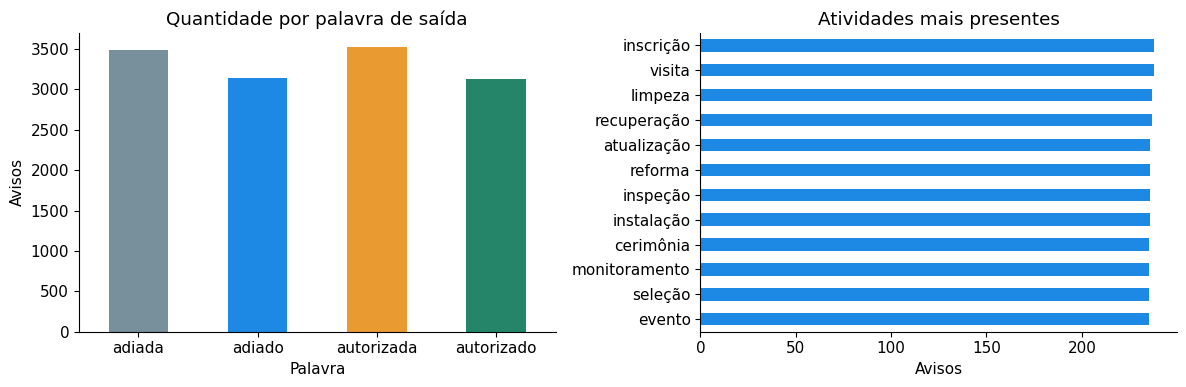

In [5]:
# @title
fig, ax = plt.subplots(1,2,figsize=(12,4))
dados[alvo].value_counts().sort_index().plot.bar(ax=ax[0],color=CORES,rot=0)
ax[0].set(title='Quantidade por palavra de saída',ylabel='Avisos',xlabel='Palavra')
dados.palavra_1.value_counts().head(12).sort_values().plot.barh(ax=ax[1],color=CORES[1])
ax[1].set(title='Atividades mais presentes',xlabel='Avisos',ylabel='')
plt.tight_layout(); plt.show()

## 1.2 Treino, validação e teste

O treino ajusta os pesos. A validação escolhe configurações e acompanha o aprendizado. O teste fica reservado para a comparação final. A divisão considera o contexto completo, não apenas cada linha.

Depois da limpeza de formato, o codificador aprende o vocabulário **somente no treino**. Cada palavra recebe indicadores separados conforme sua posição. Não atribuímos uma ordem numérica artificial às palavras. Os três modelos receberão exatamente essas mesmas entradas.

In [6]:
separador = GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEMENTE)
desenv_idx, teste_idx = next(separador.split(dados,groups=dados.contexto))
desenvolvimento = dados.iloc[desenv_idx]
separador_val = GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEMENTE+1)
tr_rel, val_rel = next(separador_val.split(desenvolvimento,groups=desenvolvimento.contexto))
treino = desenvolvimento.iloc[tr_rel].copy()
validacao = desenvolvimento.iloc[val_rel].copy()
teste = dados.iloc[teste_idx].copy()
assert not (set(treino.contexto)&set(validacao.contexto))
assert not (set(treino.contexto)&set(teste.contexto))
assert not (set(validacao.contexto)&set(teste.contexto))
display(pd.DataFrame({'Partição':['Treino','Validação','Teste'],
    'Registros':[len(treino),len(validacao),len(teste)],
    'Contextos':[x.contexto.nunique() for x in [treino,validacao,teste]]}))
codificador = OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
X_treino = codificador.fit_transform(treino[entradas])
X_val = codificador.transform(validacao[entradas])
y_treino, y_val = treino[alvo].to_numpy(), validacao[alvo].to_numpy()
classes = np.sort(treino[alvo].unique())
print('Quantidade de entradas numéricas por aviso:',X_treino.shape[1])
display(pd.DataFrame(codificador.transform(treino[entradas].head(3)),
    columns=codificador.get_feature_names_out(),index=treino.contexto.head(3)).loc[:,lambda x:x.any()])

,Partição,Registros,Contextos
0,Treino,7961,2736
1,Validação,2662,912
2,Teste,2660,912


Quantidade de entradas numéricas por aviso: 99


,palavra_1_limpeza,palavra_1_manutenção,palavra_1_recapeamento,palavra_2_com,palavra_2_sem,palavra_3_instabilidade,palavra_3_interdição,palavra_3_veículo
contexto,,,,,,,,
recapeamento sem veículo,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
limpeza com instabilidade,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
manutenção sem interdição,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


## 1.3 Treinar cada modelo separadamente

Vamos usar as configurações escolhidas pela validação na versão anterior: regressão logística com `C=0.1`, árvore sem limite de profundidade e com pelo menos cinco exemplos por folha, e MLP com camadas de 128 e 64 neurônios. Assim, não repetimos a busca de configurações a cada execução da aula.

Cada modelo tem sua própria célula e seu cronômetro. A mesma preparação e a mesma divisão dos dados continuam valendo para todos. Na rede, vamos separar o tempo de ajuste dos pesos do tempo gasto para medir e desenhar os resultados.

In [7]:
selecionados = {}
tempos_modelos = {}

### Regressão logística

In [8]:
print('Treinando a regressão logística...',flush=True)
inicio_celula=time.perf_counter()
modelo_logistico=LogisticRegression(C=.1,max_iter=600)
inicio=time.perf_counter()
modelo_logistico.fit(X_treino,y_treino)
tempo_logistica=time.perf_counter()-inicio
f1_logistica=f1_score(y_val,modelo_logistico.predict(X_val),average='macro',zero_division=0)
selecionados['Regressão logística']={'modelo':modelo_logistico,'f1':f1_logistica,
    'segundos':tempo_logistica,'config':'C=0.1'}
tempos_modelos['Regressão logística']={'Ajuste dos pesos/regras (s)':tempo_logistica,
    'Treino e acompanhamento (s)':time.perf_counter()-inicio_celula}
print(f'Treinamento concluído em {tempo_logistica:.3f} s. F1 na validação: {percentual(f1_logistica)}.')

Treinando a regressão logística...
Treinamento concluído em 5.165 s. F1 na validação: 44,9%.


### Árvore de decisão

In [9]:
print('Treinando a árvore de decisão...',flush=True)
inicio_celula=time.perf_counter()
modelo_arvore=DecisionTreeClassifier(max_depth=None,min_samples_leaf=5,random_state=SEMENTE)
inicio=time.perf_counter()
modelo_arvore.fit(X_treino,y_treino)
tempo_arvore=time.perf_counter()-inicio
f1_arvore=f1_score(y_val,modelo_arvore.predict(X_val),average='macro',zero_division=0)
selecionados['Árvore de decisão']={'modelo':modelo_arvore,'f1':f1_arvore,
    'segundos':tempo_arvore,'config':'profundidade=None, folha=5'}
tempos_modelos['Árvore de decisão']={'Ajuste dos pesos/regras (s)':tempo_arvore,
    'Treino e acompanhamento (s)':time.perf_counter()-inicio_celula}
print(f'Treinamento concluído em {tempo_arvore:.3f} s. F1 na validação: {percentual(f1_arvore)}.')
print(f'A árvore tem {modelo_arvore.tree_.node_count} nós e profundidade {modelo_arvore.get_depth()}.')

Treinando a árvore de decisão...
Treinamento concluído em 0.115 s. F1 na validação: 67,2%.
A árvore tem 413 nós e profundidade 73.


## 1.4 Rede neural: acompanhar cada época

Nesta célula, a rede treina uma época por vez. Ao terminar cada passagem pelo treino, o painel atualiza **perda, acurácia, F1 e tempo da época**. O gráfico azul acompanha o treino e o laranja acompanha a validação.

Perda menor é melhor. Acurácia e F1 maiores são melhores. Se a perda de treino cai e a de validação sobe, a rede está se ajustando demais aos exemplos conhecidos. Vamos guardar os pesos com menor perda de validação e parar após 20 épocas sem melhora relevante.

O teste fica reservado até o término do treinamento. Na etapa seguinte, veremos também sua evolução por época, usando as versões da rede que foram guardadas. Como esta base tem um padrão controlado, a acurácia pode estabilizar cedo. A perda ainda ajuda a perceber mudanças na confiança das previsões.

In [10]:
def mostrar_epoca(historico,melhor_epoca,limite,sem_melhora,tempo_total):
    h=pd.DataFrame(historico)
    fig,ax=plt.subplots(2,2,figsize=(12,7))
    for eixo,metrica,titulo in [(ax[0,0],'Perda','Perda (menor é melhor)'),
                                (ax[0,1],'Acurácia','Acurácia'),(ax[1,0],'F1','F1 macro')]:
        eixo.plot(h['Época'],h[f'{metrica} de treino'],label='Treino',color='#1976D2',marker='o',markersize=3)
        eixo.plot(h['Época'],h[f'{metrica} de validação'],label='Validação',color='#E99B32',marker='o',markersize=3)
        eixo.axvline(melhor_epoca,color='gray',linestyle='--',label='Melhores pesos até agora')
        eixo.set(title=titulo,xlabel='Época',xlim=(.7,max(2,len(h))+.3))
        if metrica!='Perda':
            eixo.set_ylim(0,1.04)
            eixo.yaxis.set_major_formatter(PercentFormatter(1))
        eixo.legend(fontsize=8)
    ax[1,1].bar(h['Época'],h['Treino da época (s)'],color='#258568')
    ax[1,1].set(title='Tempo de ajuste em cada época',xlabel='Época',ylabel='Segundos')
    fig.suptitle(f'Época {len(h)}/{limite} • {tempo_total:.1f} s decorridos • {sem_melhora}/{PACIENCIA} épocas sem melhora',fontsize=13)
    fig.tight_layout(rect=(0,0,1,.95))
    clear_output(wait=True)
    display(fig)
    plt.close(fig)
    ultimo=h.iloc[-1]
    print(f'Agora: perda de validação {ultimo["Perda de validação"]:.4f}; '
          f'acurácia {percentual(ultimo["Acurácia de validação"])}; F1 {percentual(ultimo["F1 de validação"])}.')
    print(f'Pesos escolhidos até aqui: época {melhor_epoca}. O teste ainda não foi consultado.')

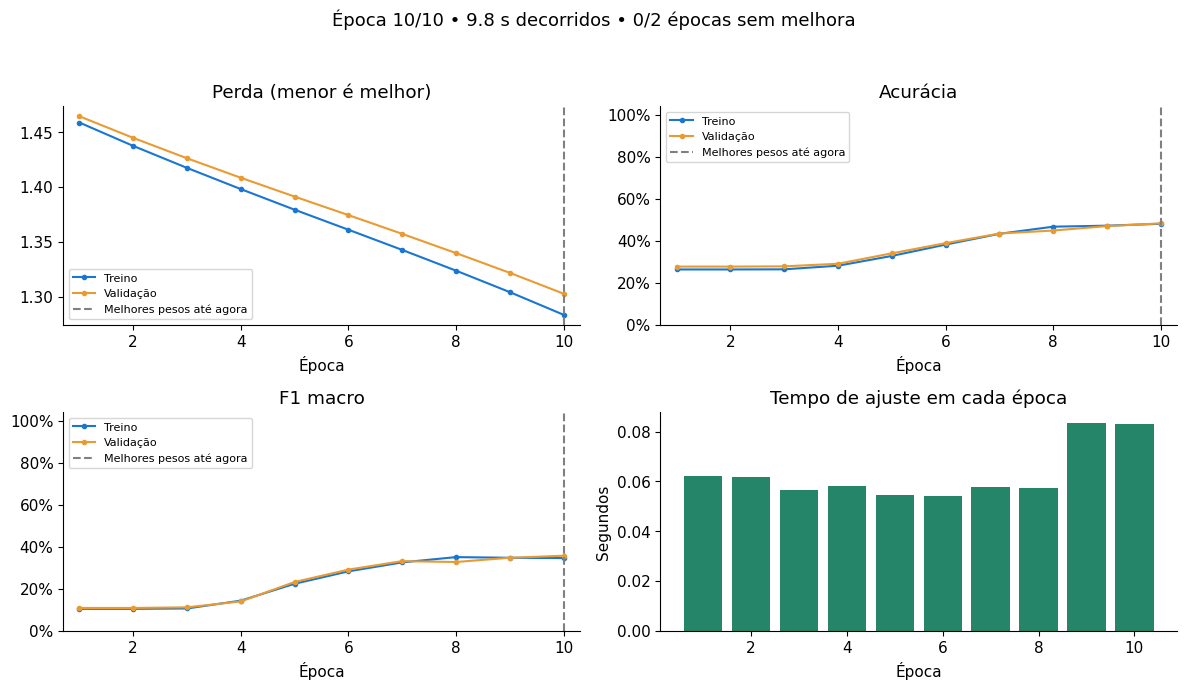

Agora: perda de validação 1.3027; acurácia 48,3%; F1 35,7%.
Pesos escolhidos até aqui: época 10. O teste ainda não foi consultado.
Concluído: 10 épocas. Pesos preservados da época 10.
Ajuste dos pesos: 0.63 s. Com avaliação e gráficos: 10.61 s.


In [11]:
MAX_EPOCAS=10
PACIENCIA=2
arquitetura=(5,4)
rede=MLPClassifier(hidden_layer_sizes=arquitetura,activation='relu',solver='adam',
    alpha=.01,learning_rate_init=.0003,batch_size=128,random_state=SEMENTE)
historico=[]
redes_por_epoca=[]
melhor_perda=np.inf
sem_melhora=0
inicio_rede=time.perf_counter()
print('Iniciando a primeira época...',flush=True)
for epoca in range(1,MAX_EPOCAS+1):
    inicio_epoca=time.perf_counter()
    rede.partial_fit(X_treino,y_treino,classes=classes)
    tempo_epoca=time.perf_counter()-inicio_epoca
    pt,pv=rede.predict_proba(X_treino),rede.predict_proba(X_val)
    pred_t,pred_v=rede.classes_[pt.argmax(1)],rede.classes_[pv.argmax(1)]
    perda_t=log_loss(y_treino,pt,labels=rede.classes_)
    perda_v=log_loss(y_val,pv,labels=rede.classes_)
    historico.append({'Época':epoca,'Perda de treino':perda_t,'Perda de validação':perda_v,
        'Acurácia de treino':accuracy_score(y_treino,pred_t),'Acurácia de validação':accuracy_score(y_val,pred_v),
        'F1 de treino':f1_score(y_treino,pred_t,average='macro'),
        'F1 de validação':f1_score(y_val,pred_v,average='macro'),'Treino da época (s)':tempo_epoca})
    redes_por_epoca.append(copy.deepcopy(rede))
    if perda_v<melhor_perda-.0001:
        melhor_perda=perda_v
        melhor_rede=copy.deepcopy(rede)
        melhor_epoca=epoca
        sem_melhora=0
    else:
        sem_melhora+=1
    mostrar_epoca(historico,melhor_epoca,MAX_EPOCAS,sem_melhora,time.perf_counter()-inicio_rede)
    if sem_melhora>=PACIENCIA:
        break
tempo_total_rede=time.perf_counter()-inicio_rede
historico=pd.DataFrame(historico)
tempo_rede=float(historico['Treino da época (s)'].sum())
selecionados['Rede neural MLP']={'modelo':melhor_rede,
    'f1':f1_score(y_val,melhor_rede.predict(X_val),average='macro'),
    'segundos':tempo_rede,'config':str(arquitetura)}
tempos_modelos['Rede neural MLP']={'Ajuste dos pesos/regras (s)':tempo_rede,
    'Treino e acompanhamento (s)':tempo_total_rede}
print(f'Concluído: {len(historico)} épocas. Pesos preservados da época {melhor_epoca}.')
print(f'Ajuste dos pesos: {tempo_rede:.2f} s. Com avaliação e gráficos: {tempo_total_rede:.2f} s.')

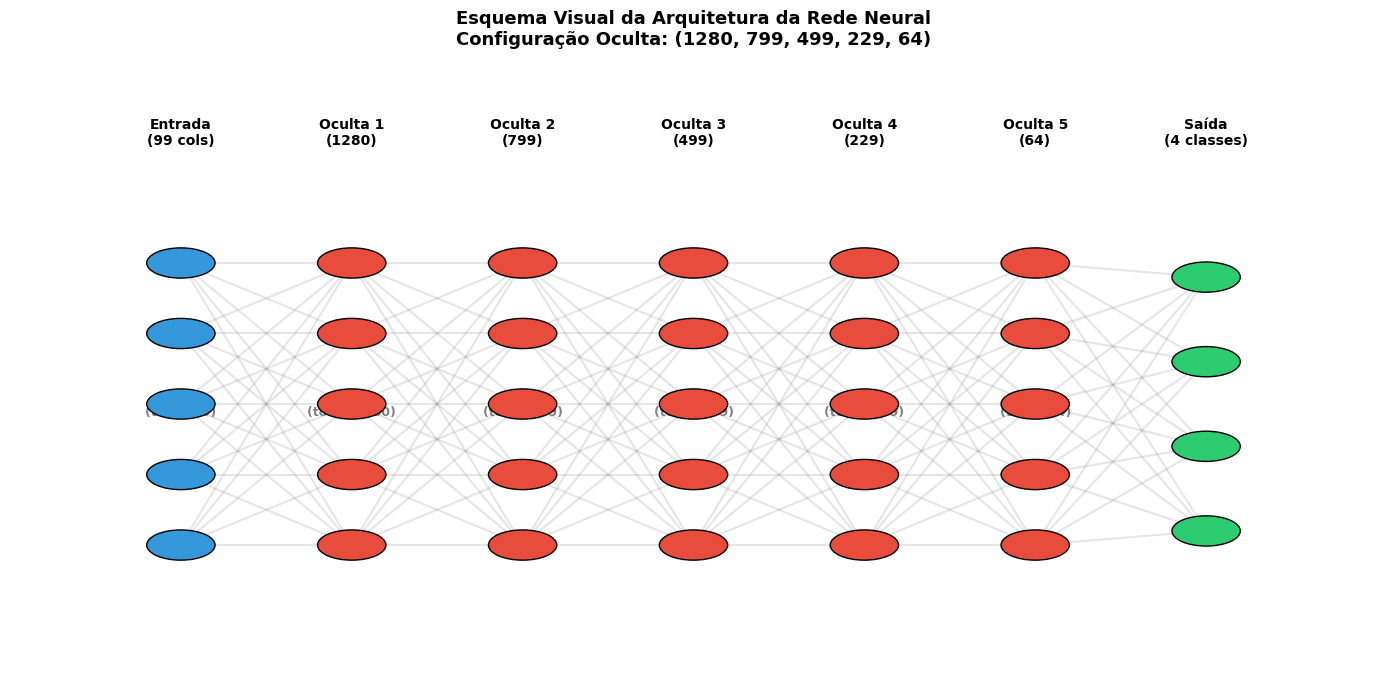

In [12]:
# @title
import matplotlib.pyplot as plt
import numpy as np


def desenhar_arquitetura_rede(
    arquitetura, n_entradas=10, n_saidas=3, max_nos_visiveis=5
):
  """Gera um gráfico dinâmico da arquitetura da rede neural para apresentações.

  - arquitetura: tupla com os neurónios das camadas ocultas (ex: (1280, 799,
  ...))
  - n_entradas: número de colunas/features dos seus dados (X_treino.shape[1])
  - n_saidas: número de classes do seu problema (len(classes))
  - max_nos_visiveis: limite de círculos desenhados por camada para não poluir o
  gráfico
  """
  # Monta a lista completa: [Entrada, Camada 1, Camada 2, ..., Saída]
  tamanhos_camadas = [n_entradas] + list(arquitetura) + [n_saidas]
  nomes_camadas = (
      [f"Entrada\n({n_entradas} cols)"]
      + [f"Oculta {i+1}\n({t})" for i, t in enumerate(arquitetura)]
      + [f"Saída\n({n_saidas} classes)"]
  )

  fig, ax = plt.subplots(figsize=(14, 7))
  ax.axis("off")

  n_camadas = len(tamanhos_camadas)
  espacamento_x = 1 / (n_camadas + 1)
  coords_camadas = []

  # Desenhar os nós e rótulos
  for i, tamanho in enumerate(tamanhos_camadas):
    x = (i + 1) * espacamento_x
    y_coords = []

    # Define se desenha todos ou resume com reticências
    if tamanho <= max_nos_visiveis:
      num_desenhar = tamanho
      mostrar_reticencias = False
    else:
      num_desenhar = max_nos_visiveis
      mostrar_reticencias = True

    espacamento_y = 0.7 / (num_desenhar + 1)

    for j in range(num_desenhar):
      y = 0.8 - (j + 1) * espacamento_y
      y_coords.append((x, y))

      # Cores diferentes para Entrada (Azul), Ocultas (Vermelho/Laranja) e Saída (Verde)
      if i == 0:
        cor = "#3498db"
      elif i == n_camadas - 1:
        cor = "#2ecc71"
      else:
        cor = "#e74c3c"

      circle = plt.Circle(
          (x, y), 0.025, color=cor, ec="black", zorder=4, transform=ax.transAxes
      )
      ax.add_patch(circle)

    # Adiciona reticências verticais se a camada for muito grande
    if mostrar_reticencias:
      y_mid = 0.8 - ((num_desenhar / 2) + 0.5) * espacamento_y
      ax.text(
          x,
          y_mid,
          f"⋮\n(total: {tamanho})",
          ha="center",
          va="center",
          fontsize=9,
          weight="bold",
          color="gray",
          transform=ax.transAxes,
      )

    coords_camadas.append(y_coords)

    # Título de cada camada no topo
    ax.text(
        x,
        0.90,
        nomes_camadas[i],
        ha="center",
        va="center",
        fontsize=10,
        weight="bold",
        transform=ax.transAxes,
    )

  # Desenhar as linhas de conexão entre os nós visíveis
  for i in range(len(coords_camadas) - 1):
    camada_atual = coords_camadas[i]
    proxima_camada = coords_camadas[i + 1]

    for pt1 in camada_atual:
      for pt2 in proxima_camada:
        ax.plot(
            [pt1[0], pt2[0]],
            [pt1[1], pt2[1]],
            color="gray",
            alpha=0.2,
            zorder=1,
            transform=ax.transAxes,
        )

  plt.title(
      f"Esquema Visual da Arquitetura da Rede Neural\nConfiguração Oculta:"
      f" {arquitetura}",
      fontsize=13,
      weight="bold",
      pad=20,
  )
  plt.tight_layout()
  plt.show()


# === COMO USAR NO SEU CÓDIGO ===
# Basta chamar a função passando a sua variável 'arquitetura'
# (Dica: substitua X_treino.shape[1] e len(classes) pelos valores reais do seu projeto)

arquitetura = (1280, 799, 499, 229, 64)
desenhar_arquitetura_rede(
    arquitetura,
    n_entradas=X_treino.shape[1],
    n_saidas=len(np.unique(y_treino)),
)

In [13]:
print('Tempo de cada modelo nesta execução:')
display(pd.DataFrame.from_dict(tempos_modelos,orient='index').round(3))
print('Histórico completo das épocas:')
display(historico.round(4))

Tempo de cada modelo nesta execução:


,Ajuste dos pesos/regras (s),Treino e acompanhamento (s)
Regressão logística,5.165,5.209
Árvore de decisão,0.115,0.134
Rede neural MLP,0.629,10.605


Histórico completo das épocas:


,Época,Perda de treino,Perda de validação,Acurácia de treino,Acurácia de validação,F1 de treino,F1 de validação,Treino da época (s)
0,1,1.4587,1.4644,0.2632,0.2769,0.1042,0.1084,0.0621
1,2,1.4374,1.4447,0.2632,0.2769,0.1042,0.1084,0.0618
2,3,1.4173,1.4261,0.2638,0.2780,0.1059,0.1114,0.0565
3,4,1.3980,1.4083,0.2810,0.2904,0.1433,0.1396,0.0583
4,5,1.3792,1.3912,0.3276,0.3400,0.2236,0.2320,0.0545
5,6,1.3610,1.3743,0.3816,0.3884,0.2827,0.2910,0.0541
6,7,1.3426,1.3572,0.4330,0.4343,0.3254,0.3314,0.0577
7,8,1.3237,1.3397,0.4669,0.4485,0.3505,0.3273,0.0573
8,9,1.3041,1.3216,0.4717,0.4696,0.3474,0.3475,0.0836
9,10,1.2834,1.3027,0.4807,0.4827,0.3458,0.3571,0.0831


## 1.5 Evolução no teste, depois do treinamento

Os pesos já foram escolhidos pela validação. Agora vamos avaliar no teste cada versão da rede guardada durante o treino. As curvas abaixo comparam **treino e teste por época**, sem fazer novos ajustes.

A linha tracejada marca a escolha feita antes de consultar o teste. Não trocaremos os pesos pelo ponto que parecer melhor nesta figura. Ela serve para entender o comportamento do modelo em exemplos reservados.

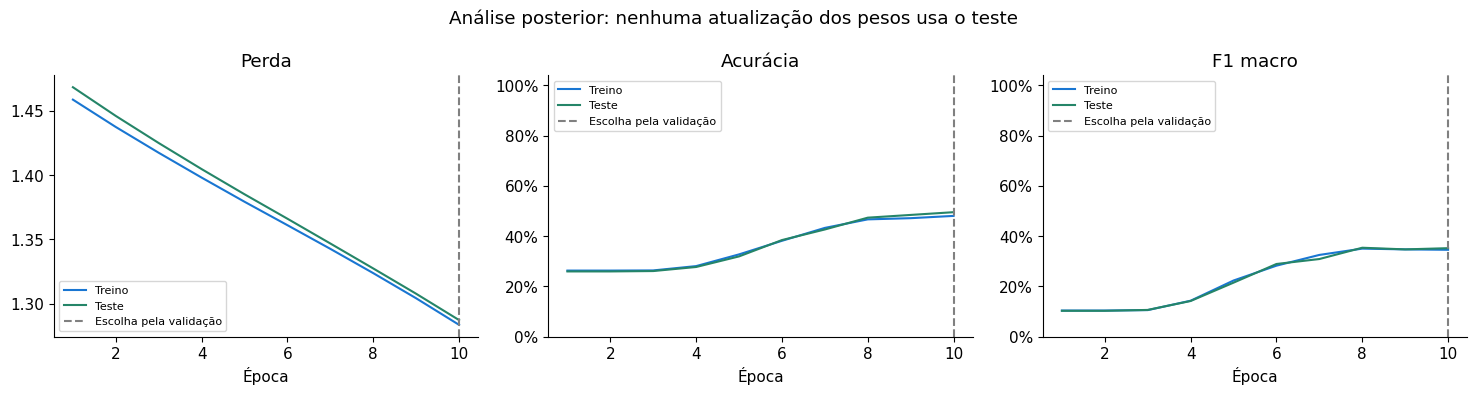

,Época,Perda de treino,Perda de teste,Acurácia de treino,Acurácia de teste,F1 de treino,F1 de teste
9,10,1.2834,1.2871,0.4807,0.4955,0.3458,0.3523


In [14]:
X_teste=codificador.transform(teste[entradas])
y_teste=teste[alvo].to_numpy()
historico_teste=[]
for epoca,rede_salva in enumerate(redes_por_epoca,1):
    probabilidades=rede_salva.predict_proba(X_teste)
    pred=rede_salva.classes_[probabilidades.argmax(1)]
    historico_teste.append({'Época':epoca,'Perda de teste':log_loss(y_teste,probabilidades,labels=rede_salva.classes_),
        'Acurácia de teste':accuracy_score(y_teste,pred),'F1 de teste':f1_score(y_teste,pred,average='macro')})
historico_teste=pd.DataFrame(historico_teste)
evolucao=historico.merge(historico_teste,on='Época',validate='one_to_one')
fig,ax=plt.subplots(1,3,figsize=(15,4))
for eixo,metrica in zip(ax,['Perda','Acurácia','F1']):
    eixo.plot(evolucao['Época'],evolucao[f'{metrica} de treino'],label='Treino',color='#1976D2')
    eixo.plot(evolucao['Época'],evolucao[f'{metrica} de teste'],label='Teste',color='#258568')
    eixo.axvline(melhor_epoca,color='gray',linestyle='--',label='Escolha pela validação')
    eixo.set(title=metrica if metrica!='F1' else 'F1 macro',xlabel='Época')
    if metrica!='Perda':
        eixo.set_ylim(0,1.04);eixo.yaxis.set_major_formatter(PercentFormatter(1))
    eixo.legend(fontsize=8)
plt.suptitle('Análise posterior: nenhuma atualização dos pesos usa o teste')
plt.tight_layout();plt.show()
display(evolucao.loc[evolucao['Época'].eq(melhor_epoca),
    ['Época','Perda de treino','Perda de teste','Acurácia de treino','Acurácia de teste','F1 de treino','F1 de teste']].round(4))

## 1.6 Comparação final no teste

**Acurácia** é a proporção de próximas palavras corretas. **Precisão** pergunta se as previsões de uma classe estão corretas. **Revocação** verifica quantos exemplos daquela classe foram encontrados. **F1** reúne precisão e revocação. Nas médias macro, cada classe tem o mesmo peso.

O **acerto entre as três sugestões** aceita que a palavra correta esteja em qualquer uma das três primeiras posições. Como só temos quatro saídas, essa tarefa é bem mais fácil e precisa ser lida junto da acurácia da primeira sugestão. Uma probabilidade alta indica a preferência do modelo, não uma garantia de acerto.

,Acurácia,Precisão macro,Revocação macro,F1 macro,Acerto entre 3,Ajuste (s),Previsão total (s),Estrutura
Modelo,,,,,,,,
Classe mais frequente,0.2598,0.0649,0.2500,0.1031,0.7680,0.0077,0.0002,Uma classe fixa
Regressão logística,0.4376,0.4370,0.4372,0.4364,1.0000,5.1652,0.0106,400 parâmetros
Árvore de decisão,0.6523,0.6449,0.6437,0.6418,1.0000,0.1149,0.0012,413 nós
Rede neural MLP,0.4955,0.3192,0.4883,0.3523,0.7402,0.6289,0.0083,544 parâmetros


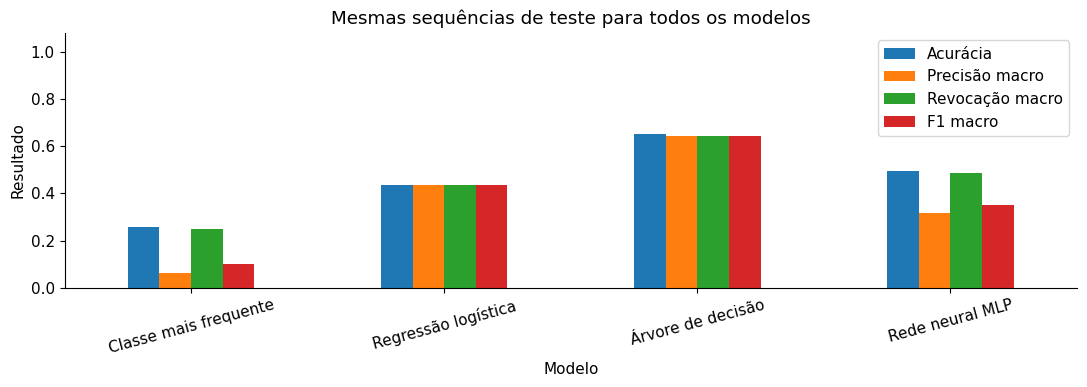

Ajuste (s) mede apenas o treinamento. O tempo com métricas e gráficos aparece na tabela anterior. Os tempos variam conforme a máquina.


In [15]:
inicio_referencia=time.perf_counter()
referencia = DummyClassifier(strategy='most_frequent').fit(X_treino,y_treino)
tempo_referencia=time.perf_counter()-inicio_referencia
modelos = {'Classe mais frequente':referencia,
           **{nome:info['modelo'] for nome,info in selecionados.items()}}
X_teste = codificador.transform(teste[entradas]); y_teste=teste[alvo].to_numpy()
resultados = []; previsoes = {}
for nome,modelo in modelos.items():
    inicio=time.perf_counter();prob=modelo.predict_proba(X_teste)
    tempo_previsao=time.perf_counter()-inicio
    pred=modelo.classes_[prob.argmax(1)];previsoes[nome]=pred
    top3=modelo.classes_[np.argsort(-prob,axis=1)[:,:3]]
    complexidade = (f'{modelo.tree_.node_count} nós' if hasattr(modelo,'tree_') else
        f'{sum(w.size for w in modelo.coefs_)+sum(b.size for b in modelo.intercepts_):,} parâmetros' if hasattr(modelo,'coefs_') else
        f'{modelo.coef_.size+modelo.intercept_.size} parâmetros' if hasattr(modelo,'coef_') else 'Uma classe fixa')
    resultados.append({'Modelo':nome,'Acurácia':accuracy_score(y_teste,pred),
        'Precisão macro':precision_score(y_teste,pred,average='macro',zero_division=0),
        'Revocação macro':recall_score(y_teste,pred,average='macro',zero_division=0),
        'F1 macro':f1_score(y_teste,pred,average='macro',zero_division=0),
        'Acerto entre 3':np.mean((top3==y_teste[:,None]).any(1)),
        'Ajuste (s)':selecionados.get(nome,{}).get('segundos',tempo_referencia),
        'Previsão total (s)':tempo_previsao,'Estrutura':complexidade})
comparacao = pd.DataFrame(resultados).set_index('Modelo')
display(comparacao.round(4))
comparacao[['Acurácia','Precisão macro','Revocação macro','F1 macro']].plot.bar(ylim=(0,1.08),rot=15)
plt.title('Mesmas sequências de teste para todos os modelos');plt.ylabel('Resultado');plt.tight_layout();plt.show()
print('Ajuste (s) mede apenas o treinamento. O tempo com métricas e gráficos aparece na tabela anterior. Os tempos variam conforme a máquina.')

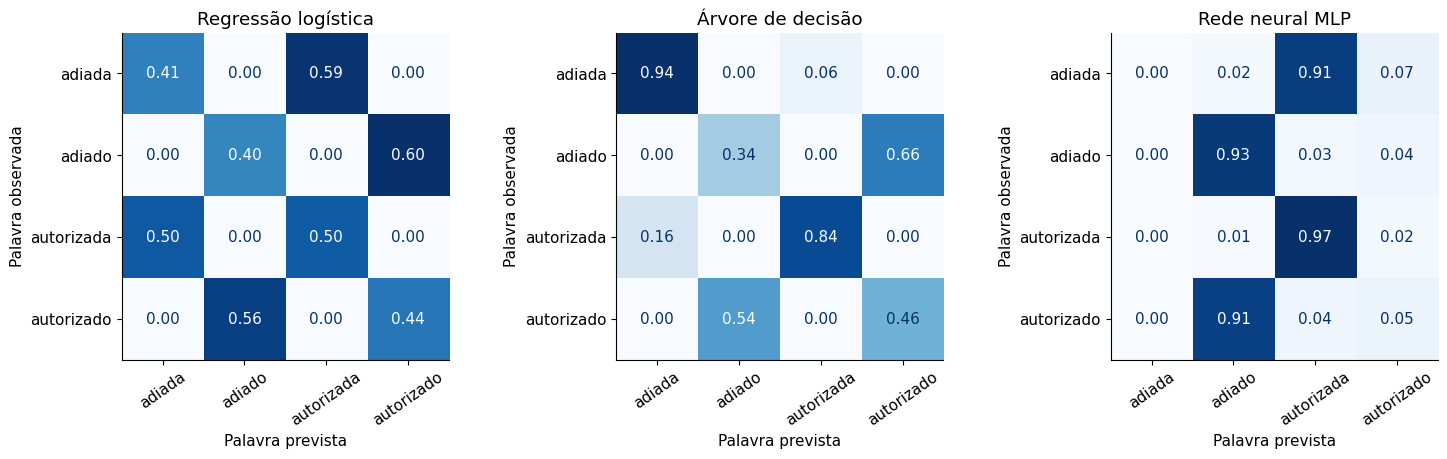

,Precisão,Revocação,F1,Exemplos
adiada,0.853,0.941,0.895,691.000
adiado,0.400,0.337,0.366,661.000
autorizada,0.934,0.838,0.883,691.000
autorizado,0.393,0.459,0.423,617.000
accuracy,0.652,0.652,0.652,0.652
macro avg,0.645,0.644,0.642,2660.000
weighted avg,0.655,0.652,0.651,2660.000


Modelo escolhido pela validação: Árvore de decisão


In [16]:
fig,ax=plt.subplots(1,3,figsize=(15,4.6))
for eixo,nome in zip(ax,selecionados):
    ConfusionMatrixDisplay.from_predictions(y_teste,previsoes[nome],labels=classes,
        display_labels=classes,normalize='true',cmap='Blues',values_format='.2f',
        colorbar=False,ax=eixo)
    eixo.set(title=nome,xlabel='Palavra prevista',ylabel='Palavra observada')
    eixo.tick_params(axis='x',rotation=35)
plt.tight_layout();plt.show()
vencedor = max(selecionados,key=lambda n:selecionados[n]['f1'])
relatorio = pd.DataFrame(classification_report(y_teste,previsoes[vencedor],output_dict=True,zero_division=0)).T
display(relatorio.rename(columns={'precision':'Precisão','recall':'Revocação','f1-score':'F1','support':'Exemplos'}).round(3))
print('Modelo escolhido pela validação:',vencedor)

Na matriz, cada linha é a palavra que realmente apareceu, e cada coluna é a palavra prevista. A diagonal mostra os acertos. Os valores são proporções dentro de cada linha. Uma linha com muitos valores fora da diagonal revela uma classe que o modelo confunde.

Não há uma nota universal que torne um modelo “bom”. Neste exercício, precisamos superar a referência simples, acertar as quatro classes e manter a vantagem em contextos inéditos. Depois disso, observamos os erros e lembramos que o teste ainda pertence a uma base sintética.

A comparação mantém a representação inicial igual para todos. Uma regressão logística com variáveis que descrevessem explicitamente as interações poderia melhorar. O que estamos observando aqui é a capacidade da rede de aprender essas combinações a partir dos indicadores de palavras, sem recebê-las prontas.

In [17]:
acc_rede=comparacao.loc['Rede neural MLP','Acurácia']
outro=comparacao.loc[['Regressão logística','Árvore de decisão'],'Acurácia'].idxmax()
ganho=acc_rede-comparacao.loc[outro,'Acurácia']
print(f'A rede acertou {percentual(acc_rede)} das próximas palavras no teste.')
print(f'O melhor dos outros dois modelos foi {outro}, com {percentual(comparacao.loc[outro,"Acurácia"])}.')
print(f'A diferença a favor da rede foi de {100*ganho:.1f} pontos percentuais.')
print('Conclusão: a comparação acima mostra o ganho obtido neste vocabulário e nesta divisão.')
print('Os erros restantes podem envolver desfechos ambíguos ou padrões que a rede não aprendeu.')
analise=teste[['contexto',alvo]].copy()
for nome in selecionados:analise[nome]=previsoes[nome]
print('Exemplos em que a rede acertou:')
display(analise[analise['Rede neural MLP']==analise[alvo]].head(5))
print('Exemplos em que a rede errou:')
display(analise[analise['Rede neural MLP']!=analise[alvo]].head(5))

A rede acertou 49,5% das próximas palavras no teste.
O melhor dos outros dois modelos foi Árvore de decisão, com 65,2%.
A diferença a favor da rede foi de -15.7 pontos percentuais.
Conclusão: a comparação acima mostra o ganho obtido neste vocabulário e nesta divisão.
Os erros restantes podem envolver desfechos ambíguos ou padrões que a rede não aprendeu.
Exemplos em que a rede acertou:


,contexto,proxima_palavra,Regressão logística,Árvore de decisão,Rede neural MLP
4,recapeamento com risco,adiado,adiado,autorizado,adiado
9,inscrição sem interrupção,autorizada,autorizada,adiada,autorizada
15,revisão sem impedimento,autorizada,adiada,autorizada,autorizada
17,transporte com defeito,adiado,autorizado,autorizado,adiado
38,concurso com interrupção,adiado,autorizado,autorizado,adiado


Exemplos em que a rede errou:


,contexto,proxima_palavra,Regressão logística,Árvore de decisão,Rede neural MLP
11,pagamento sem interdição,autorizado,autorizado,autorizado,adiado
12,remanejamento sem licença,adiado,adiado,autorizado,autorizada
13,capacitação com interrupção,adiada,autorizada,adiada,autorizada
19,operação com defeito,adiada,autorizada,adiada,autorizada
56,plantio sem pendência,autorizado,adiado,autorizado,adiado


## 1.7 O que muda dentro dos modelos

A figura da árvore mostra apenas os primeiros níveis. Em uma coluna de indicação de palavra, um valor acima de 0,5 significa que aquela palavra está presente na posição indicada. O ramo da esquerda corresponde à condição verdadeira. `exemplos` informa quantos exemplos chegaram ao nó e `classe` indica a classe predominante.

Na rede, cada ligação tem um peso e cada neurônio treinável tem um viés. O mapa de cores abaixo mostra parte dos pesos da primeira camada. A cor identifica sinal e intensidade. Um peso isolado não explica a decisão inteira, porque as camadas seguintes combinam várias ativações.

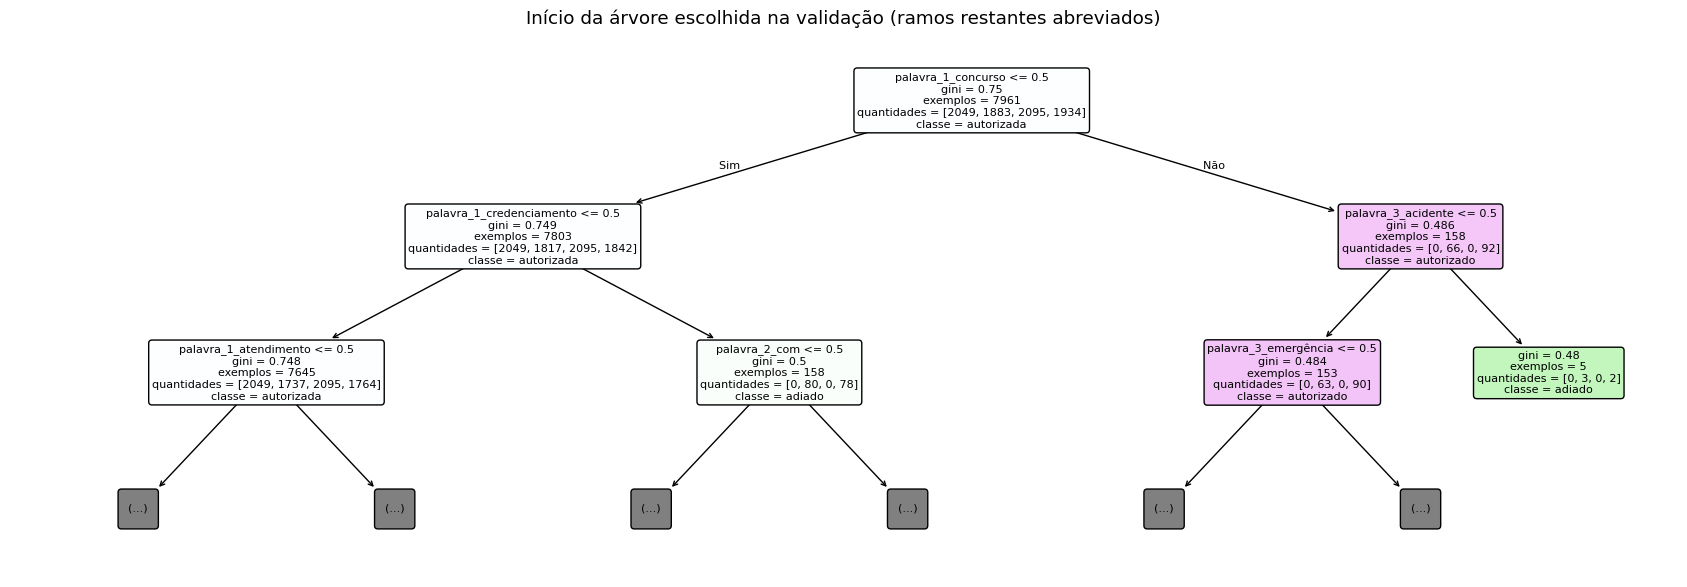

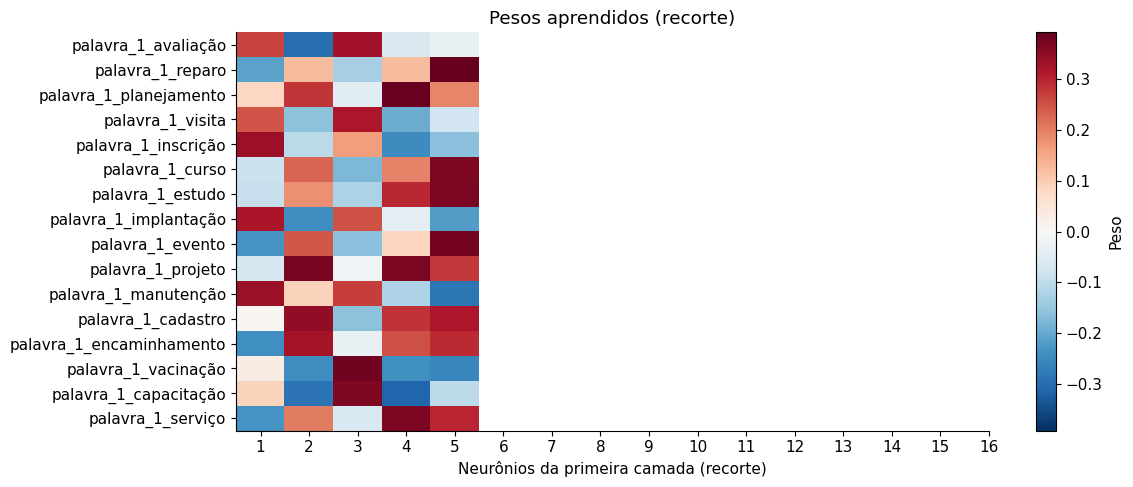

In [18]:
fig,ax=plt.subplots(figsize=(17,6))
elementos = plot_tree(modelos['Árvore de decisão'],max_depth=2,
    feature_names=codificador.get_feature_names_out(),class_names=classes,
    filled=True,rounded=True,fontsize=8,ax=ax)
for elemento in elementos:
    elemento.set_text(elemento.get_text().replace('samples =','exemplos =')
        .replace('value =','quantidades =').replace('class =','classe =')
        .replace('True','Sim').replace('False','Não'))
ax.set_title('Início da árvore escolhida na validação (ramos restantes abreviados)')
plt.tight_layout();plt.show()
pesos=modelos['Rede neural MLP'].coefs_[0]
indices=np.argsort(np.abs(pesos).mean(axis=1))[-16:]
fig,ax=plt.subplots(figsize=(12,5))
limite=np.abs(pesos[indices,:16]).max()
img=ax.imshow(pesos[indices,:16],cmap='RdBu_r',aspect='auto',vmin=-limite,vmax=limite)
ax.set_yticks(range(16),codificador.get_feature_names_out()[indices])
ax.set(xticks=range(16),xticklabels=range(1,17),xlabel='Neurônios da primeira camada (recorte)',title='Pesos aprendidos (recorte)')
fig.colorbar(img,ax=ax,label='Peso');plt.tight_layout();plt.show()

## 1.8 Digitar um novo aviso

Use três palavras no formato da base, por exemplo **vistoria sem equipe**, **reforma com risco** ou **curso com material**. Vamos apresentar as três respostas mais prováveis de cada modelo. Se a palavra não existir no vocabulário de sua posição, o programa avisará e pedirá outro exemplo.

Digite o aviso [vistoria sem equipe]: vistoria sem equipe


,Modelo,Posição,Sugestão,Probabilidade estimada
0,Regressão logística,1,adiada,0.4799
1,Regressão logística,2,autorizada,0.3959
2,Regressão logística,3,adiado,0.0746
3,Árvore de decisão,1,adiada,0.9767
4,Árvore de decisão,2,autorizada,0.0233
5,Árvore de decisão,3,adiado,0.0000
6,Rede neural MLP,1,autorizada,0.3356
7,Rede neural MLP,2,autorizado,0.2583
8,Rede neural MLP,3,adiado,0.2282


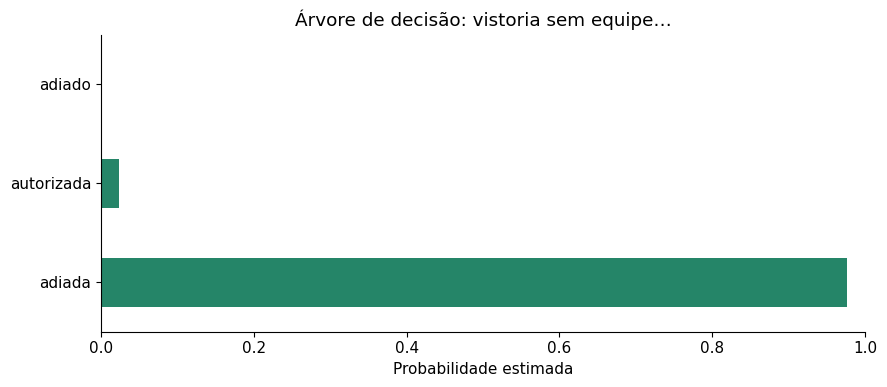

In [19]:
def sugerir_palavras(frase):
    partes=re.sub(r'\s+',' ',frase.lower()).strip().split(' ')
    if len(partes)!=3:
        raise ValueError('Digite exatamente três palavras: atividade, com/sem e condição.')
    desconhecidas=[p for i,p in enumerate(partes) if p not in codificador.categories_[i]]
    if desconhecidas:
        raise ValueError('Palavras fora do vocabulário dessa posição: '+', '.join(desconhecidas))
    x=codificador.transform(pd.DataFrame([partes],columns=entradas))
    linhas=[]
    for nome,modelo in modelos.items():
        if nome=='Classe mais frequente':continue
        prob=modelo.predict_proba(x)[0]
        for pos,idx in enumerate(np.argsort(-prob)[:3],1):
            linhas.append({'Modelo':nome,'Posição':pos,'Sugestão':modelo.classes_[idx],
                           'Probabilidade estimada':prob[idx]})
    return pd.DataFrame(linhas)

while True:
    frase=input('Digite o aviso [vistoria sem equipe]: ').strip() or 'vistoria sem equipe'
    try:
        sugestoes=sugerir_palavras(frase)
        display(sugestoes.round(4))
        break
    except ValueError as erro:
        print(erro)
fig,ax=plt.subplots(figsize=(9,4))
sugestoes[sugestoes.Modelo.eq(vencedor)].plot.barh(x='Sugestão',y='Probabilidade estimada',ax=ax,color=CORES[3],legend=False)
ax.set(xlim=(0,1),title=f'{vencedor}: {frase}…',xlabel='Probabilidade estimada',ylabel='')
plt.tight_layout();plt.show()

# 2. Reclamações semelhantes e assuntos recorrentes

Uma mesma reclamação pode ser escrita de várias maneiras. Vamos comparar a busca por palavras, com **TF-IDF + KNN**, e a busca por significado, com uma **rede neural de textos + KNN**. Os dois métodos consultarão o mesmo acervo e devolverão cinco relatos diferentes.

Continuaremos com `Aula_17_Reclamacoes.xlsx`. A aba de auditoria guarda os temas para conferir os resultados; esses temas não entram na representação dos textos. Nossa meta nesta atividade é alcançar **70% de Precisão@5** na busca neural.

,reclamacao_id,texto,bairro,dias_desde_relato
0,R02689,"Este problema precisa de atenção. A lâmpada do poste está queimada e a rua fica escura. Local: setor 269, no bairro Canasvieiras. Outros moradores também no...",Canasvieiras,1.0
1,R00234,"Registro o que está acontecendo. A roda caiu numa abertura profunda no meio da pista. Local: setor 366, no bairro Tapera.",Tapera,80.0
2,R09100,"Registro o que está acontecendo. Há sacos de lixo acumulados há vários dias. Local: setor 25, no bairro Tapera.",Tapera,38.0
3,R08653,"A poda precisa retirar os galhos secos que podem cair. Local: setor 326, no bairro Córrego Grande. Já fiz contato anteriormente. Gostaria de acrescentar que...",Córrego Grande,19.0
4,R02843,"Peço uma verificação da prefeitura. A drenagem da via não dá conta da chuva. Local: setor 171, no bairro Canasvieiras. Outros moradores também notaram a sit...",Canasvieiras,107.0


,Ausentes,Percentual
reclamacao_id,0,0.0
texto,110,1.1
bairro,250,2.5
dias_desde_relato,300,3.0


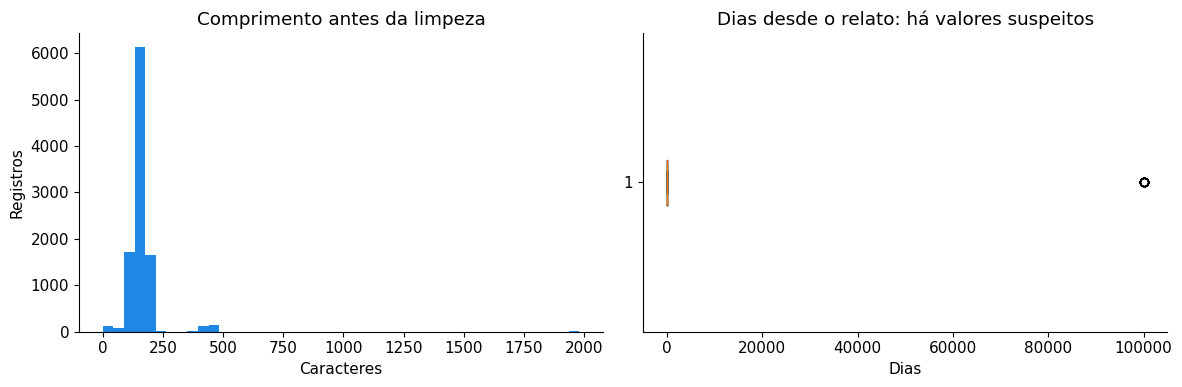

In [20]:
arquivo_reclamacoes=localizar('Aula_17_Reclamacoes.xlsx')
reclamacoes_brutas=pd.read_excel(arquivo_reclamacoes,sheet_name='reclamacoes')
auditoria=pd.read_excel(arquivo_reclamacoes,sheet_name='auditoria')
display(reclamacoes_brutas.head())
display(pd.DataFrame({'Ausentes':reclamacoes_brutas.isna().sum(),
    'Percentual':(100*reclamacoes_brutas.isna().mean()).round(2)}))
fig,ax=plt.subplots(1,2,figsize=(12,4))
comprimento=reclamacoes_brutas.texto.fillna('').str.len()
ax[0].hist(comprimento,bins=45,color=CORES[1]);ax[0].set(title='Comprimento antes da limpeza',xlabel='Caracteres',ylabel='Registros')
ax[1].boxplot(reclamacoes_brutas.dias_desde_relato.dropna(),orientation='horizontal')
ax[1].set(title='Dias desde o relato: há valores suspeitos',xlabel='Dias')
plt.tight_layout();plt.show()

## 2.1. Limpeza dos registros

Excluímos registros sem conteúdo, propaganda e duplicatas. Dias negativos ou superiores ao período de 120 dias da coleta ficam como ausentes. Não precisamos preencher esses dias: a busca utilizará o relato. Textos longos não serão excluídos apenas pelo tamanho.

Sem texto suficiente: 120 | Propaganda: 12
Dias incompatíveis com a coleta: 28
Registros disponíveis após a limpeza: 9837


,texto
8101,"peço uma verificação da prefeitura. a superfície da pista tem desníveis que fazem os carros baterem embaixo. local: setor 342, no bairro lagoa da conceição...."
2783,"venho solicitar uma providência. aparelhos amplificados no estabelecimento fazem vibrar os vidros até de madrugada. local: setor 118, no bairro santo antôni..."


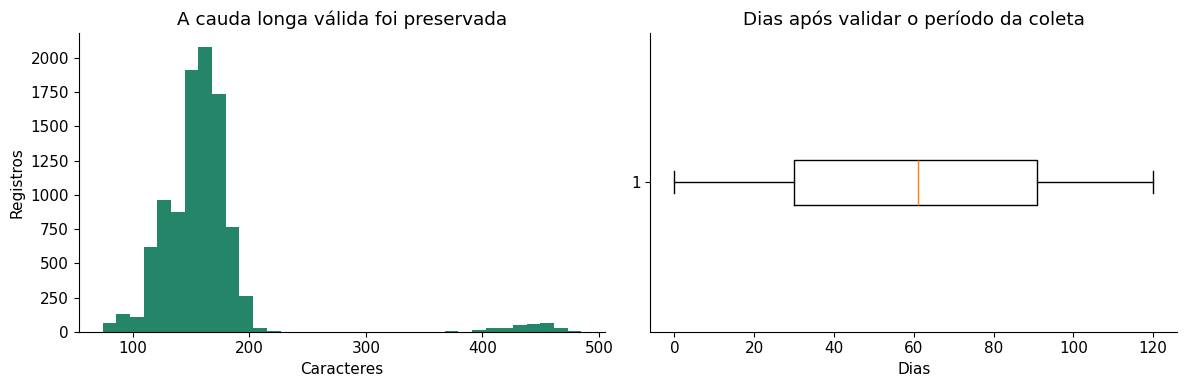

In [23]:
# @title
reclamacoes=reclamacoes_brutas.drop_duplicates('reclamacao_id').copy()
reclamacoes['texto']=(reclamacoes.texto.fillna('').str.lower()
                      .str.replace(r'\s+',' ',regex=True).str.strip())
sem_conteudo=reclamacoes.texto.str.len().lt(20)
propaganda=reclamacoes.texto.str.contains('promoção clique aqui',regex=False)
print('Sem texto suficiente:',int(sem_conteudo.sum()),'| Propaganda:',int(propaganda.sum()))
reclamacoes=reclamacoes[~sem_conteudo & ~propaganda].drop_duplicates('texto').reset_index(drop=True)
invalidos=~reclamacoes.dias_desde_relato.between(0,120) & reclamacoes.dias_desde_relato.notna()
print('Dias incompatíveis com a coleta:',int(invalidos.sum()))
reclamacoes.loc[invalidos,'dias_desde_relato']=np.nan
reclamacoes['bairro']=reclamacoes.bairro.fillna('Não informado')
print('Registros disponíveis após a limpeza:',len(reclamacoes))
display(reclamacoes.loc[reclamacoes.texto.str.len().nlargest(2).index,['texto']])
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(reclamacoes.texto.str.len(),bins=35,color=CORES[3]);ax[0].set(title='A cauda longa válida foi preservada',xlabel='Caracteres',ylabel='Registros')
ax[1].boxplot(reclamacoes.dias_desde_relato.dropna(),orientation='horizontal');ax[1].set(title='Dias após validar o período da coleta',xlabel='Dias')
plt.tight_layout();plt.show()

## 2.2. O problema deve pesar mais que a forma de escrever

O número do setor, o bairro e expressões como “peço uma verificação da prefeitura” aparecem em reclamações de assuntos diferentes. Se entrarem na comparação, podem aproximar relatos que não tratam do mesmo problema.

Vamos criar uma segunda coluna com o conteúdo do relato. A lista de frases neutras abaixo foi conferida nos registros de referência; **não vamos retirar palavras de negação**, como “não” e “sem”. O texto original continua guardado para consulta.

In [24]:
reclamacoes = reclamacoes.merge(auditoria, on='reclamacao_id', validate='one_to_one')
assert reclamacoes.tema_referencia.notna().all()
assert set(reclamacoes.particao) == {'referencia', 'validacao', 'teste'}

FRASES_NEUTRAS = set([
    "agradeço se puderem verificar",
    "este problema precisa de atenção",
    "gostaria de acrescentar que esta situação já foi observada em mais de uma ocasião",
    "gostaria de registrar uma situação",
    "já fiz contato anteriormente",
    "não sabemos qual é a previsão de atendimento e solicitamos retorno quando houver uma definição",
    "o problema continua sem solução",
    "os moradores organizaram os relatos para informar o endereço e aguardam uma visita da equipe responsável",
    "outros moradores também notaram a situação",
    "peço uma verificação da prefeitura",
    "precisamos de uma resposta sobre o atendimento",
    "registro o que está acontecendo",
    "venho solicitar uma providência"
])

def preparar_relato(texto):
    texto = re.sub(r'\s+', ' ', str(texto).lower()).strip()
    texto = re.sub(r'\blocal\s*:\s*[^.!?]*(?:[.!?]|$)', ' ', texto)
    frases = [f.strip() for f in re.split(r'[.!?]+', texto) if f.strip()]
    return '. '.join(f for f in frases if f not in FRASES_NEUTRAS)

reclamacoes['texto_modelo'] = reclamacoes.texto.map(preparar_relato)
assert reclamacoes.texto_modelo.str.len().ge(10).all()
display(reclamacoes[['texto', 'texto_modelo']].head(3))

,texto,texto_modelo
0,"este problema precisa de atenção. a lâmpada do poste está queimada e a rua fica escura. local: setor 269, no bairro canasvieiras. outros moradores também no...",a lâmpada do poste está queimada e a rua fica escura
1,"registro o que está acontecendo. a roda caiu numa abertura profunda no meio da pista. local: setor 366, no bairro tapera.",a roda caiu numa abertura profunda no meio da pista
2,"registro o que está acontecendo. há sacos de lixo acumulados há vários dias. local: setor 25, no bairro tapera.",há sacos de lixo acumulados há vários dias


## 2.3. Referência, validação e teste

Esta base é simulada e repete formas de escrever o mesmo relato, mudando o endereço ou a introdução. Depois da limpeza, manteremos **uma ocorrência de cada relato distinto por partição**. Assim, a busca não devolve cinco cópias, e uma frase repetida muitas vezes não pesa mais na avaliação.

A referência é o acervo consultado. A validação serve para escolher a configuração; o teste fica reservado para a comparação final. As partições fornecidas na base são preservadas, com famílias de redação diferentes. A tabela mostra quantos exemplos distintos realmente temos para avaliar.

In [25]:
for a, b in [('referencia', 'validacao'), ('referencia', 'teste'), ('validacao', 'teste')]:
    pa = reclamacoes[reclamacoes.particao.eq(a)]
    pb = reclamacoes[reclamacoes.particao.eq(b)]
    assert not (set(pa.familia_redacao) & set(pb.familia_redacao))
    assert not (set(pa.texto_modelo) & set(pb.texto_modelo))

base_textos = reclamacoes.drop_duplicates(['particao', 'texto_modelo']).reset_index(drop=True)
textos = base_textos.texto_modelo.to_numpy()
ref_idx = np.flatnonzero(base_textos.particao.eq('referencia'))
val_idx = np.flatnonzero(base_textos.particao.eq('validacao'))
tes_idx = np.flatnonzero(base_textos.particao.eq('teste'))
temas_auditoria = base_textos.tema_referencia.to_numpy()
classes_tema = np.sort(np.unique(temas_auditoria[ref_idx]))
K_VIZINHOS = 5
META_PRECISAO = 0.70
resumo_particoes = reclamacoes.groupby('particao').agg(Registros=('reclamacao_id','size'))
resumo_particoes['Relatos distintos'] = base_textos.groupby('particao').size()
resumo_particoes['Temas na auditoria'] = base_textos.groupby('particao').tema_referencia.nunique()
display(resumo_particoes.loc[['referencia','validacao','teste']])
print('Cada relato distinto conta uma vez. Nenhuma família de redação aparece em duas partições.')

,Registros,Relatos distintos,Temas na auditoria
particao,,,
referencia,6144,80,8
validacao,1844,24,8
teste,1849,24,8


Cada relato distinto conta uma vez. Nenhuma família de redação aparece em duas partições.


## 2.4. TF-IDF + KNN

O TF-IDF representa palavras e pequenos trechos de palavras. O KNN encontra os cinco relatos mais próximos nessa representação. Ajustamos o vocabulário somente na referência e medimos a validação em outra célula, sem utilizar o teste.

In [26]:
from sklearn.pipeline import FeatureUnion
import unicodedata

palavras_frequentes = 'a o as os um uma uns umas de do da dos das em no na nos nas por para ao aos à às e ou que se com daqui nesta neste essa esse esta este é está estão estava ficou há muito mais já ser foi são pela pelo pelos pelas'.split()
palavras_frequentes = sorted(set(
    ''.join(c for c in unicodedata.normalize('NFKD', p) if not unicodedata.combining(c))
    for p in palavras_frequentes))

print('Ajustando a representação lexical e o índice de vizinhos...', flush=True)
inicio = time.perf_counter()
tfidf = FeatureUnion([
    ('palavras', TfidfVectorizer(ngram_range=(1,2), min_df=1,
        stop_words=palavras_frequentes, strip_accents='unicode', sublinear_tf=True)),
    ('caracteres', TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5),
        min_df=1, sublinear_tf=True))
], transformer_weights={'palavras':0.7, 'caracteres':0.3})
X_ref_lexical = tfidf.fit_transform(textos[ref_idx])
indice_lexical = NearestNeighbors(n_neighbors=K_VIZINHOS, metric='cosine',
    algorithm='brute').fit(X_ref_lexical)
tempo_tfidf = time.perf_counter()-inicio
print(f'TF-IDF e índice prontos em {tempo_tfidf:.3f} s.')

inicio = time.perf_counter()
idx_val_l = indice_lexical.kneighbors(tfidf.transform(textos[val_idx]), return_distance=False)
p_val_l = (temas_auditoria[ref_idx][idx_val_l] == temas_auditoria[val_idx,None]).mean()
tempo_validacao_tfidf = time.perf_counter()-inicio
print('Precisão@5 na validação:', percentual(p_val_l))

Ajustando a representação lexical e o índice de vizinhos...
TF-IDF e índice prontos em 0.032 s.
Precisão@5 na validação: 36,7%


## 2.5. Rede neural de textos + KNN

Uma rede já treinada transforma cada relato em um vetor que representa seu significado. Com esses vetores, o KNN pode aproximar maneiras diferentes de descrever o mesmo problema. Vamos usar **paraphrase-multilingual-mpnet-base-v2**, um modelo multilíngue escolhido pela validação.

Aqui não treinamos os pesos da rede: usamos uma representação pré-treinada. Por isso, acompanharemos o carregamento, a geração dos vetores e a busca, sem uma curva de épocas. Só precisamos processar os relatos distintos; os vetores ficam em cache para as próximas execuções.

In [27]:
print('Importando as bibliotecas da rede neural...', flush=True)
import torch
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='IProgress not found.*')
    import sentence_transformers
    from sentence_transformers import SentenceTransformer

torch.set_num_threads(4)
dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
nome_rede = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'
revisao_rede = '4328cf26390c98c5e3c738b4460a05b95f4911f5'
prefixo_rede = ''
print(f'Carregando {nome_rede} em {dispositivo}. O primeiro uso exige download.', flush=True)
inicio = time.perf_counter()
rede_texto = SentenceTransformer(nome_rede, revision=revisao_rede, device=dispositivo)
tempo_carga = time.perf_counter()-inicio
print(f'Rede carregada em {tempo_carga:.2f} s.')
entradas_rede = [prefixo_rede+t for t in textos]
tokens = rede_texto.tokenizer(entradas_rede, truncation=False, padding=False)['input_ids']
print('Relatos distintos:',len(textos),'| Limite da rede:',rede_texto.max_seq_length,'tokens')
print('Textos acima do limite:',sum(len(t)>rede_texto.max_seq_length for t in tokens))

Importando as bibliotecas da rede neural...
Carregando sentence-transformers/paraphrase-multilingual-mpnet-base-v2 em cpu. O primeiro uso exige download.


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Rede carregada em 20.32 s.
Relatos distintos: 128 | Limite da rede: 128 tokens
Textos acima do limite: 0


In [28]:
USAR_CACHE = True
pasta_cache = Path('.cache_aula17')
pasta_cache.mkdir(exist_ok=True)
assinatura = {'modelo':nome_rede, 'revisao':revisao_rede,
    'limite':rede_texto.max_seq_length, 'normalizados':True,
    'biblioteca':sentence_transformers.__version__, 'entradas':entradas_rede}
chave = hashlib.sha256(json.dumps(assinatura,ensure_ascii=False,sort_keys=True).encode('utf-8')).hexdigest()
arquivo_cache = pasta_cache/f'caso2_{chave[:20]}.npz'
usou_cache = False
tempo_cache = tempo_vetores = 0.
if USAR_CACHE and arquivo_cache.exists():
    inicio = time.perf_counter()
    try:
        with np.load(arquivo_cache,allow_pickle=False) as salvo:
            vetores = salvo['vetores']
            assert str(salvo['chave'].item()) == chave
            assert vetores.shape == (len(textos),rede_texto.get_sentence_embedding_dimension())
            assert np.isfinite(vetores).all()
            tempo_geracao_original = float(salvo['tempo_geracao'])
        usou_cache = True
        tempo_cache = time.perf_counter()-inicio
        print(f'Cache carregado em {tempo_cache:.3f} s. Geração original: {tempo_geracao_original:.2f} s.')
    except (OSError,ValueError,KeyError,AssertionError):
        print('Cache incompatível: os vetores serão gerados novamente.')

if not usou_cache:
    inicio = time.perf_counter()
    blocos = []
    painel = display(HTML('Iniciando a representação dos relatos...'),display_id=True)
    for primeiro in range(0,len(textos),32):
        ultimo = min(primeiro+32,len(textos))
        blocos.append(rede_texto.encode(entradas_rede[primeiro:ultimo],batch_size=32,
            normalize_embeddings=True,show_progress_bar=False))
        painel.update(HTML(f'<b>Rede neural: {ultimo} de {len(textos)} relatos</b>'
            f'<br><progress value="{ultimo}" max="{len(textos)}" style="width:90%"></progress>'
            f'<br>Tempo decorrido: {time.perf_counter()-inicio:.1f} s.'))
    vetores = np.vstack(blocos).astype(np.float32)
    tempo_vetores = time.perf_counter()-inicio
    tempo_geracao_original = tempo_vetores
    np.savez_compressed(arquivo_cache,vetores=vetores,chave=chave,tempo_geracao=tempo_vetores)
    print(f'Vetores gerados em {tempo_vetores:.2f} s e salvos em cache.')
print('Formato:',vetores.shape)

Vetores gerados em 15.18 s e salvos em cache.
Formato: (128, 768)


In [29]:
inicio = time.perf_counter()
indice_neural = NearestNeighbors(n_neighbors=K_VIZINHOS,metric='cosine',
    algorithm='brute').fit(vetores[ref_idx])
tempo_indice_neural = time.perf_counter()-inicio
inicio = time.perf_counter()
idx_val_n = indice_neural.kneighbors(vetores[val_idx],return_distance=False)
p_val_n = (temas_auditoria[ref_idx][idx_val_n] == temas_auditoria[val_idx,None]).mean()
tempo_validacao_neural = time.perf_counter()-inicio
display(pd.DataFrame({'Método':['TF-IDF + KNN','Rede neural + KNN'],
    'Precisão@5 na validação':[percentual(p_val_l),percentual(p_val_n)]}))
display(pd.DataFrame([
    ['TF-IDF: representação e índice',tempo_tfidf],
    ['TF-IDF: consulta de validação',tempo_validacao_tfidf],
    ['Rede neural: carregamento',tempo_carga],
    ['Rede neural: geração nesta execução',tempo_vetores],
    ['Rede neural: leitura do cache',tempo_cache],
    ['Rede neural: índice',tempo_indice_neural],
    ['Rede neural: consulta de validação, com vetores prontos',tempo_validacao_neural]
],columns=['Etapa','Segundos']).round(3))
print('A leitura do cache não substitui a medida do custo original de geração dos vetores.')

,Método,Precisão@5 na validação
0,TF-IDF + KNN,"36,7%"
1,Rede neural + KNN,"80,0%"


,Etapa,Segundos
0,TF-IDF: representação e índice,0.032
1,TF-IDF: consulta de validação,0.014
2,Rede neural: carregamento,20.318
3,Rede neural: geração nesta execução,15.179
4,Rede neural: leitura do cache,0.000
5,Rede neural: índice,0.007
6,"Rede neural: consulta de validação, com vetores prontos",0.031


A leitura do cache não substitui a medida do custo original de geração dos vetores.


## 2.6. A busca encontrou o assunto certo?

**Precisão@5** responde: dos cinco relatos devolvidos, quantos tratam do assunto da consulta? Se quatro forem pertinentes, a precisão daquela busca será 80%. Tiramos a média de todas as consultas de teste. Já **Acerto@1** considera somente a primeira sugestão. Encontrar pelo menos um relato correto entre cinco é uma medida menos exigente e aparece em outra coluna.

Também faremos uma simulação de classificação: o tema mais frequente entre os cinco vizinhos será a resposta. Nessa tarefa, calculamos acurácia, precisão, revocação e F1. As médias **macro** dão o mesmo peso a cada tema. Os rótulos entram apenas nessa conferência, depois que os vizinhos já foram encontrados.

,Precisão@5,Acerto@1,Pelo menos um em 5,Acurácia do tema,Precisão macro,Revocação macro,F1 macro
Método,,,,,,,
TF-IDF + KNN,"40,0%","70,8%","91,7%","66,7%","66,7%","66,7%","66,0%"
Rede neural + KNN,"80,0%","87,5%","100,0%","87,5%","91,9%","87,5%","87,6%"


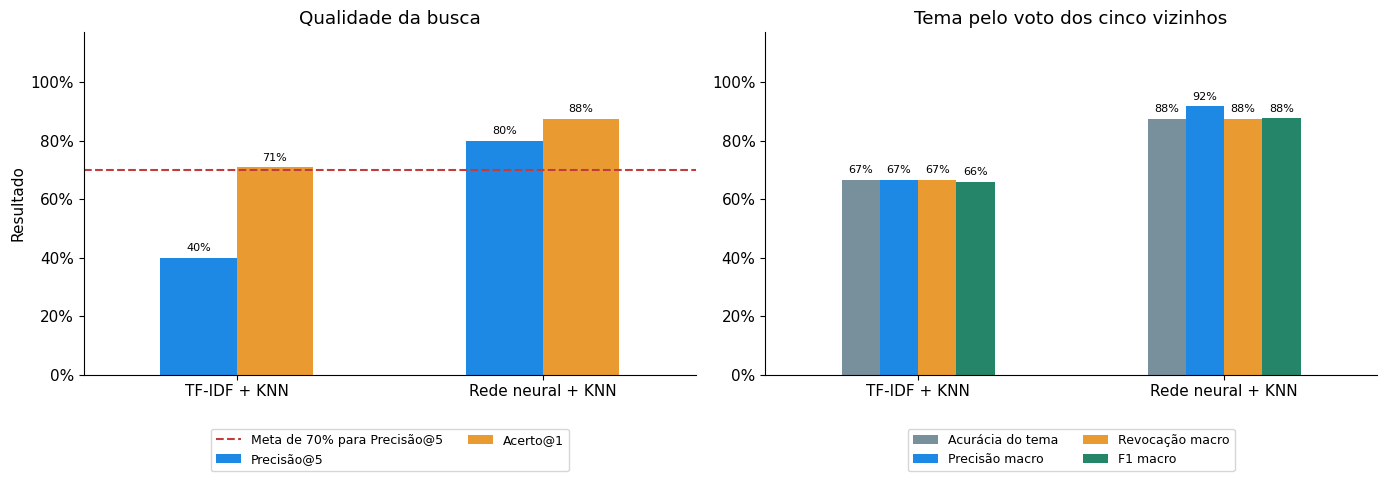

Teste: 24 relatos distintos, com cinco sugestões por relato.
Precisão@5 neural: 80,0%. Meta de 70%: atingida.
Em média, 4.00 dos cinco resultados neurais tiveram o tema correto.
Diferença em relação ao TF-IDF: +40.0 pontos percentuais.
A meta é uma referência desta atividade. A base simulada tem poucas redações distintas; não representa uma validação de uso real.


In [30]:
def votar_tema(rotulos):
    votos = []
    for linha in rotulos:
        contagem = pd.Series(linha).value_counts()
        empatados = set(contagem[contagem.eq(contagem.max())].index)
        # Em empate, prevalece o vizinho mais próximo entre os temas empatados.
        votos.append(next(tema for tema in linha if tema in empatados))
    return np.array(votos)

inicio = time.perf_counter()
dist_l, idx_l = indice_lexical.kneighbors(tfidf.transform(textos[tes_idx]))
tempo_consulta_l = time.perf_counter()-inicio
inicio = time.perf_counter()
dist_n, idx_n = indice_neural.kneighbors(vetores[tes_idx])
tempo_consulta_n = time.perf_counter()-inicio

resultados_texto, predicoes_tema = [], {}
for nome, idx in [('TF-IDF + KNN',idx_l), ('Rede neural + KNN',idx_n)]:
    rotulos = temas_auditoria[ref_idx][idx]
    acertos = rotulos == temas_auditoria[tes_idx,None]
    votos = votar_tema(rotulos)
    predicoes_tema[nome] = votos
    resultados_texto.append({'Método':nome, 'Precisão@5':acertos.mean(),
        'Acerto@1':acertos[:,0].mean(), 'Pelo menos um em 5':acertos.any(1).mean(),
        'Acurácia do tema':accuracy_score(temas_auditoria[tes_idx],votos),
        'Precisão macro':precision_score(temas_auditoria[tes_idx],votos,average='macro',zero_division=0),
        'Revocação macro':recall_score(temas_auditoria[tes_idx],votos,average='macro',zero_division=0),
        'F1 macro':f1_score(temas_auditoria[tes_idx],votos,average='macro',zero_division=0)})
comparacao_textos = pd.DataFrame(resultados_texto).set_index('Método')
display(comparacao_textos.map(percentual))

fig, ax = plt.subplots(1,2,figsize=(14,5))
comparacao_textos[['Precisão@5','Acerto@1']].plot.bar(ax=ax[0],rot=0,color=CORES[1:3])
ax[0].axhline(META_PRECISAO,color='#C13D3D',ls='--',label='Meta de 70% para Precisão@5')
ax[0].set(title='Qualidade da busca',ylabel='Resultado',xlabel='')
comparacao_textos[['Acurácia do tema','Precisão macro','Revocação macro','F1 macro']].plot.bar(
    ax=ax[1],rot=0,color=CORES)
ax[1].set(title='Tema pelo voto dos cinco vizinhos',xlabel='')
for eixo in ax:
    eixo.set_ylim(0,1.17)
    eixo.yaxis.set_major_formatter(PercentFormatter(1))
    for barras in eixo.containers:
        eixo.bar_label(barras,labels=[f'{v.get_height():.0%}' for v in barras],fontsize=8,padding=3)
    eixo.legend(loc='upper center',bbox_to_anchor=(.5,-.14),ncol=2,fontsize=9)
plt.tight_layout();plt.show()

p_lex = comparacao_textos.loc['TF-IDF + KNN','Precisão@5']
p_neu = comparacao_textos.loc['Rede neural + KNN','Precisão@5']
print(f'Teste: {len(tes_idx)} relatos distintos, com cinco sugestões por relato.')
print(f'Precisão@5 neural: {percentual(p_neu)}. Meta de 70%: {"atingida" if p_neu>=META_PRECISAO else "não atingida"}.')
print(f'Em média, {5*p_neu:.2f} dos cinco resultados neurais tiveram o tema correto.')
print(f'Diferença em relação ao TF-IDF: {100*(p_neu-p_lex):+.1f} pontos percentuais.')
print('A meta é uma referência desta atividade. A base simulada tem poucas redações distintas; não representa uma validação de uso real.')

## 2.7. Onde cada método ainda se confunde?

Cada linha da matriz reúne um tema verdadeiro. A diagonal mostra as classificações corretas; os valores fora dela mostram para onde foram os erros. Os números são proporções dentro da linha: **1,00 representa 100%**. Com poucos relatos por tema, um único erro já altera bastante o resultado.

Na tabela por tema, precisão baixa indica que outros assuntos estão sendo encaminhados indevidamente àquela categoria. Revocação baixa indica que reclamações daquela categoria estão sendo perdidas. O F1 resume o equilíbrio entre as duas medidas.

,Tema na base,Nome no gráfico
0,Coleta de resíduos,Resíduos
1,Drenagem e alagamento,Drenagem
2,Iluminação pública,Iluminação
3,Manutenção de espaços públicos,Espaços públicos
4,Pavimentação,Pavimentação
5,Poda e arborização,Arborização
6,Ruído,Ruído
7,Transporte coletivo,Transporte


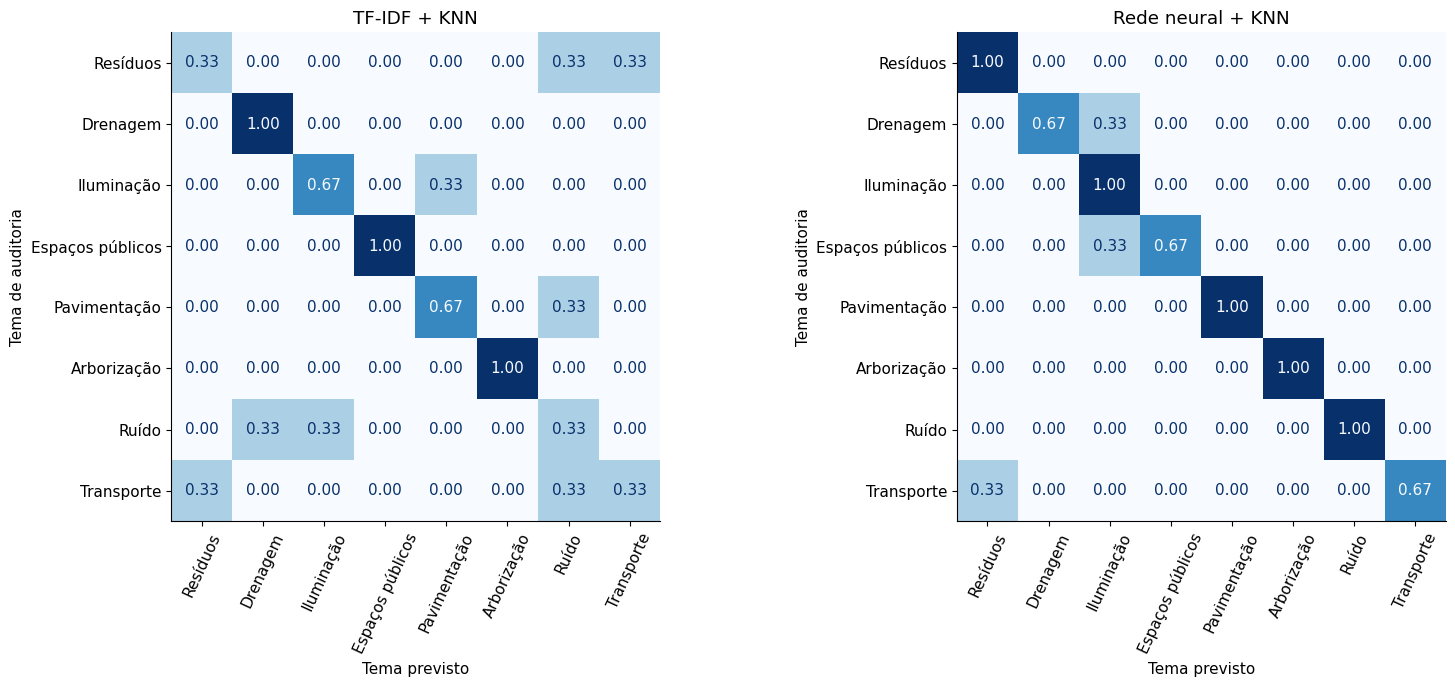

,Precisão,Revocação,F1,Consultas de teste,Precisão@5
Coleta de resíduos,75.0%,100.0%,85.7%,3,80.0%
Drenagem e alagamento,100.0%,66.7%,80.0%,3,66.7%
Iluminação pública,60.0%,100.0%,75.0%,3,100.0%
Manutenção de espaços públicos,100.0%,66.7%,80.0%,3,66.7%
Pavimentação,100.0%,100.0%,100.0%,3,100.0%
Poda e arborização,100.0%,100.0%,100.0%,3,86.7%
Ruído,100.0%,100.0%,100.0%,3,93.3%
Transporte coletivo,100.0%,66.7%,80.0%,3,46.7%


In [31]:
rotulos_curtos = ['Resíduos','Drenagem','Iluminação','Espaços públicos',
    'Pavimentação','Arborização','Ruído','Transporte']
display(pd.DataFrame({'Tema na base':classes_tema,'Nome no gráfico':rotulos_curtos}))
fig, ax = plt.subplots(1,2,figsize=(16,7))
for eixo, (nome,pred) in zip(ax,predicoes_tema.items()):
    ConfusionMatrixDisplay.from_predictions(temas_auditoria[tes_idx],pred,
        labels=classes_tema,display_labels=rotulos_curtos,normalize='true',
        cmap='Blues',colorbar=False,values_format='.2f',ax=eixo)
    eixo.set(title=nome,xlabel='Tema previsto',ylabel='Tema de auditoria')
    eixo.tick_params(axis='x',rotation=65)
plt.tight_layout();plt.show()

relatorio = pd.DataFrame(classification_report(temas_auditoria[tes_idx],
    predicoes_tema['Rede neural + KNN'],labels=classes_tema,output_dict=True,
    zero_division=0)).T.loc[classes_tema]
relatorio.columns = ['Precisão','Revocação','F1','Consultas de teste']
relatorio['Precisão@5'] = [
    (temas_auditoria[ref_idx][idx_n][temas_auditoria[tes_idx]==tema] == tema).mean()
    for tema in classes_tema]
relatorio['Consultas de teste'] = relatorio['Consultas de teste'].astype(int)
display(relatorio.style.format({c:'{:.1%}' for c in ['Precisão','Revocação','F1','Precisão@5']}))

## 2.8. Conferindo as sugestões

Vamos ler uma consulta em que os métodos mais diferiram e, em seguida, uma busca neural que ainda trouxe algum assunto incorreto. O valor de semelhança serve para ordenar os resultados; **não é uma probabilidade de acerto**.

In [32]:
acertos_l = temas_auditoria[ref_idx][idx_l] == temas_auditoria[tes_idx,None]
acertos_n = temas_auditoria[ref_idx][idx_n] == temas_auditoria[tes_idx,None]
exemplo = int(np.argmax(acertos_n.mean(1)-acertos_l.mean(1)))
print('Consulta:',textos[tes_idx[exemplo]])
print('Tema de auditoria:',temas_auditoria[tes_idx[exemplo]])
for nome, idx, dist in [('TF-IDF + KNN',idx_l,dist_l),('Rede neural + KNN',idx_n,dist_n)]:
    print(nome)
    display(pd.DataFrame({'Relato recuperado':textos[ref_idx[idx[exemplo]]],
        'Tema de auditoria':temas_auditoria[ref_idx[idx[exemplo]]],
        'Semelhança':1-dist[exemplo]}).round(3))

erros = np.flatnonzero(~acertos_n.all(1))
if len(erros):
    i = int(erros[0]); j = int(np.flatnonzero(~acertos_n[i])[0])
    display(pd.DataFrame({'Consulta':[textos[tes_idx[i]]],
        'Sugestão incorreta':[textos[ref_idx[idx_n[i,j]]]],
        'Tema esperado':[temas_auditoria[tes_idx[i]]],
        'Tema sugerido':[temas_auditoria[ref_idx[idx_n[i,j]]]],
        'Posição na busca':[j+1]}))
else:
    print('Não houve erro de tema entre os cinco vizinhos neste teste. Ainda precisamos avaliar relatos reais e novos assuntos.')

Consulta: os veículos sacodem muito ao atravessar as falhas no chão da avenida
Tema de auditoria: Pavimentação
TF-IDF + KNN


,Relato recuperado,Tema de auditoria,Semelhança
0,a camada de asfalto está esfarelando na passagem dos veículos,Pavimentação,0.339
1,a iluminação da praça falha todas as noites,Iluminação pública,0.027
2,o barulho se repete todas as noites até muito tarde,Ruído,0.022
3,há som muito alto durante a madrugada,Ruído,0.021
4,o intervalo entre os ônibus ficou muito longo,Transporte coletivo,0.019


Rede neural + KNN


,Relato recuperado,Tema de auditoria,Semelhança
0,a camada de asfalto está esfarelando na passagem dos veículos,Pavimentação,0.859
1,o asfalto afundou e os carros precisam desviar,Pavimentação,0.851
2,o asfalto cedeu perto do cruzamento,Pavimentação,0.779
3,há um buraco grande no asfalto da rua,Pavimentação,0.766
4,a pavimentação está quebrada em vários pontos,Pavimentação,0.747


,Consulta,Sugestão incorreta,Tema esperado,Tema sugerido,Posição na busca
0,não há lugar para embarcar no veículo que leva os moradores ao centro,a coleta seletiva não está passando no bairro,Transporte coletivo,Coleta de resíduos,1


## 2.9. Organizando os relatos em grupos

Agora usamos os mesmos vetores no K-means, sem informar os temas. A silhueta compara a proximidade de cada relato ao próprio grupo com sua proximidade a outros grupos. Valores mais altos indicam grupos mais separados; próximos de zero sugerem sobreposição; negativos indicam que alguns relatos se parecem mais com outro grupo.

Escolheremos a maior silhueta entre as quantidades testadas, usando somente a referência. Isso não garante que cada grupo corresponda a um serviço da prefeitura: precisamos ler seus exemplos centrais. **Silhueta não é acurácia.**

Ajustando K-means com 4 grupos...
Ajustando K-means com 6 grupos...
Ajustando K-means com 8 grupos...
Ajustando K-means com 10 grupos...
Ajustando K-means com 12 grupos...


,Grupos,Silhueta,Segundos
0,4,0.219,0.146
1,6,0.252,0.196
2,8,0.277,0.196
3,10,0.265,0.211
4,12,0.234,0.242


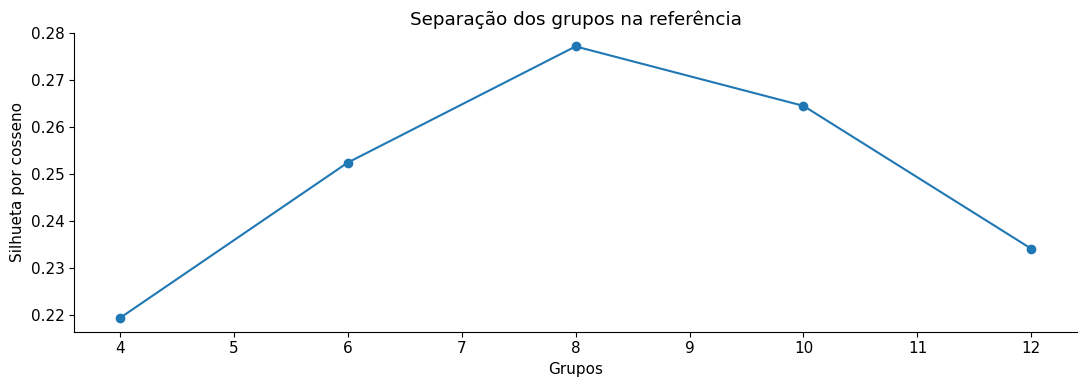

,Grupo,Relatos distintos,Exemplo central 1,Exemplo central 2
0,1,9,o ônibus da linha não passou no horário previsto,o ônibus não cumpriu o itinerário divulgado
1,2,14,as luzes dos postes não acendem quando anoitece,a iluminação pública parou de funcionar na esquina
2,3,10,o ruído de equipamentos continua durante a madrugada,há som muito alto durante a madrugada
3,4,9,o bueiro está entupido e a água da chuva não escoa,a água acumulada invade as casas depois da chuva
4,5,10,a pavimentação está quebrada em vários pontos,há galhos quebrados pendurados sobre a calçada
5,6,10,a árvore está inclinada e apresenta rachaduras no tronco,os galhos da árvore estão encostando nos fios
6,7,9,há um buraco grande no asfalto da rua,o asfalto afundou e os carros precisam desviar
7,8,9,o contêiner de lixo está transbordando,há sacos de lixo acumulados há vários dias


In [33]:
grupos_candidatos, resultados_grupos = {}, []
for k in [4,6,8,10,12]:
    inicio_grupo = time.perf_counter()
    print(f'Ajustando K-means com {k} grupos...',flush=True)
    candidato = KMeans(n_clusters=k,n_init=20,random_state=SEMENTE).fit(vetores[ref_idx])
    s = silhouette_score(vetores[ref_idx],candidato.labels_,metric='cosine')
    grupos_candidatos[k] = candidato
    resultados_grupos.append([k,s,time.perf_counter()-inicio_grupo])
silhuetas = pd.DataFrame(resultados_grupos,columns=['Grupos','Silhueta','Segundos'])
display(silhuetas.round(3))
k_escolhido = int(silhuetas.loc[silhuetas.Silhueta.idxmax(),'Grupos'])
agrupador = grupos_candidatos[k_escolhido]
grupos_ref = agrupador.labels_
silhuetas.plot(x='Grupos',y='Silhueta',marker='o',legend=False)
plt.ylabel('Silhueta por cosseno');plt.title('Separação dos grupos na referência')
plt.tight_layout();plt.show()
resumo = []
for grupo in range(k_escolhido):
    membros = np.flatnonzero(grupos_ref==grupo)
    dist = np.linalg.norm(vetores[ref_idx[membros]]-agrupador.cluster_centers_[grupo],axis=1)
    proximos = membros[np.argsort(dist)[:2]]
    resumo.append({'Grupo':grupo+1,'Relatos distintos':len(membros),
        'Exemplo central 1':textos[ref_idx[proximos[0]]],
        'Exemplo central 2':textos[ref_idx[proximos[1]]] if len(proximos)>1 else '—'})
display(pd.DataFrame(resumo))

## 2.10. Os grupos correspondem aos temas?

Só depois do agrupamento consultamos a auditoria. Um grupo com muitas cores reúne assuntos diferentes; vários grupos com a mesma cor podem ser subdivisões de um assunto.

O **ARI** compara a organização dos grupos com os temas conhecidos, descontando concordâncias esperadas ao acaso. Quanto mais próximo de 1, maior a correspondência; próximo de zero indica pouca correspondência além do acaso. Ele não representa um percentual de acertos e não foi usado para escolher os grupos.

Tema,Coleta de resíduos,Drenagem e alagamento,Iluminação pública,Manutenção de espaços públicos,Pavimentação,Poda e arborização,Ruído,Transporte coletivo
Grupo,,,,,,,,
1,0,0,0,0,0,0,0,9
2,1,0,10,2,0,0,0,1
3,0,0,0,0,0,0,10,0
4,0,9,0,0,0,0,0,0
5,0,0,0,8,1,1,0,0
6,0,1,0,0,0,9,0,0
7,0,0,0,0,9,0,0,0
8,9,0,0,0,0,0,0,0


Quantidade escolhida: 8 grupos | Silhueta: 0.277 | ARI: 0.796


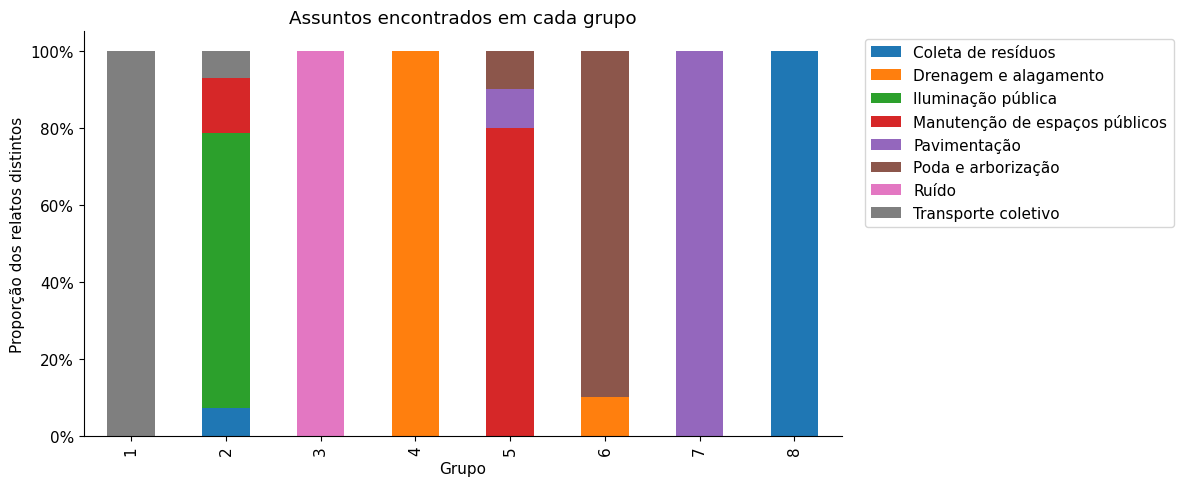

In [34]:
cruzamento = pd.crosstab(pd.Series(grupos_ref+1,name='Grupo'),
    pd.Series(temas_auditoria[ref_idx],name='Tema'))
display(cruzamento)
ari = adjusted_rand_score(temas_auditoria[ref_idx],grupos_ref)
print(f'Quantidade escolhida: {k_escolhido} grupos | Silhueta: {silhuetas.Silhueta.max():.3f} | ARI: {ari:.3f}')
if k_escolhido == silhuetas.Grupos.max():
    print('A maior silhueta ocorreu no limite superior da comparação. Isso não demonstra que encontramos a quantidade ideal de grupos.')
cruzamento.div(cruzamento.sum(axis=1),axis=0).plot.bar(stacked=True,figsize=(12,5))
plt.title('Assuntos encontrados em cada grupo');plt.ylabel('Proporção dos relatos distintos')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend(bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout();plt.show()

## 2.11. Experimente uma nova reclamação

Descreva o problema com suas próprias palavras. A mesma limpeza será aplicada à consulta. Compare os cinco resultados de cada método e observe o grupo neural mais próximo. O número do grupo não é o nome de um serviço, e a busca sempre retorna vizinhos, mesmo quando o relato fala de um assunto que não existe no acervo.

In [35]:
def buscar_reclamacao(texto,k=5):
    consulta = preparar_relato(texto)
    if len(consulta)<10:
        raise ValueError('Descreva o problema; uma saudação ou pedido de verificação não é suficiente.')
    if not isinstance(k,int) or not 1<=k<=len(ref_idx):
        raise ValueError(f'Escolha de 1 a {len(ref_idx)} vizinhos.')
    inicio = time.perf_counter()
    x_l = tfidf.transform([consulta])
    tempo_l = time.perf_counter()-inicio
    inicio = time.perf_counter()
    x_n = rede_texto.encode([prefixo_rede+consulta],normalize_embeddings=True,show_progress_bar=False)
    tempo_n = time.perf_counter()-inicio
    retornos, tempos = {}, []
    for nome, indice, x, tempo_representacao in [
        ('TF-IDF + KNN',indice_lexical,x_l,tempo_l),
        ('Rede neural + KNN',indice_neural,x_n,tempo_n)]:
        inicio = time.perf_counter()
        dist, idx = indice.kneighbors(x,n_neighbors=k)
        tempos.append({'Método':nome,'Representação + busca (s)':tempo_representacao+time.perf_counter()-inicio})
        selecao = base_textos.iloc[ref_idx[idx[0]]][['reclamacao_id','texto_modelo','bairro']].copy()
        selecao.columns = ['ID','Relato encontrado','Bairro do registro']
        selecao['Semelhança'] = 1-dist[0]
        retornos[nome] = selecao.reset_index(drop=True)
    grupo = int(agrupador.predict(x_n)[0])+1
    return retornos,grupo,pd.DataFrame(tempos)

while True:
    nova = input('Descreva a reclamação [A rua fica completamente escura à noite.]: ').strip() or 'A rua fica completamente escura à noite.'
    try:
        retornos,grupo,tempos_consulta = buscar_reclamacao(nova)
        break
    except ValueError as erro:
        print(erro)
print('Conteúdo comparado:',preparar_relato(nova))
print('Grupo mais próximo:',grupo)
for nome,tabela in retornos.items():
    print(nome);display(tabela.round(3))
display(tempos_consulta.round(4))

Descreva a reclamação [A rua fica completamente escura à noite.]: A rua fica completamente escura à noite
Conteúdo comparado: a rua fica completamente escura à noite
Grupo mais próximo: 2
TF-IDF + KNN


,ID,Relato encontrado,Bairro do registro,Semelhança
0,R02689,a lâmpada do poste está queimada e a rua fica escura,Canasvieiras,0.499
1,R06667,a rua fica alagada sempre que chove forte,Saco dos Limões,0.319
2,R01353,a luz pública está acesa de dia e apagada de noite,Capoeiras,0.139
3,R07439,uma festa mantém música alta depois da meia-noite,Ingleses,0.120
4,R02818,há um buraco grande no asfalto da rua,Lagoa da Conceição,0.107


Rede neural + KNN


,ID,Relato encontrado,Bairro do registro,Semelhança
0,R05945,a iluminação da praça falha todas as noites,Ingleses,0.769
1,R02689,a lâmpada do poste está queimada e a rua fica escura,Canasvieiras,0.761
2,R01353,a luz pública está acesa de dia e apagada de noite,Capoeiras,0.751
3,R04633,as luzes dos postes não acendem quando anoitece,Lagoa da Conceição,0.695
4,R04113,a iluminação pública parou de funcionar na esquina,Capoeiras,0.624


,Método,Representação + busca (s)
0,TF-IDF + KNN,0.0051
1,Rede neural + KNN,0.1127


**Desafio 3.**

1) Reduza o erro e aumente o F1 do desafio 1.0 através dos ajustes na rede neural, taxa de aprendizado (learning rate) e quantidade de épocas.

2) Quais ajustes você precisou fazer para obter esse resultado ? E como você explica o motivo que esses ajustes funcionaram ?